# Proyecto #1 — Exploratory Data Analysis (EDA)
## Dataset: *Predict Future Sales* (Kaggle · 1C Company)

**Integrantes:**
- Kevin Alejandro Reyes Alvarez
- Iñigo Alvarado Guirola
- Amós Nehemías Illú Chapetón

**Repositorio:** <https://github.com/kevinreyesalvarez-dot/predict-future-sales>

**Objetivo del negocio:** la cadena rusa 1C Company quiere predecir cuántas unidades venderá cada par
**tienda‑producto** en **noviembre de 2015**. Este notebook es la primera etapa: entender los datos, validar su
calidad y extraer los patrones que guiarán el modelo de forecasting.

**Variable objetivo (para la etapa de modelado):** `item_cnt_month` = suma mensual de `item_cnt_day`
por par (`shop_id`, `item_id`). En Kaggle se evalúa con RMSE y los valores reales se recortan al rango [0, 20].

| Sección | Contenido |
|---|---|
| 1 | Estructura del proyecto y repositorio |
| 2 | Comprensión inicial del dataset |
| 3 | Validación de la estructura de los datos |
| 4 | Valores faltantes, inválidos y duplicados |
| 5 | Análisis descriptivo general |
| 6 | Exploración temporal |
| 7 | Análisis comparativo entre sucursales y productos |
| 8 | Visualizaciones clave |
| 9 | ACF y PACF |
| 10 | Insights y conclusiones |

## 1. Estructura del proyecto y repositorio

**a. Plantilla cookiecutter.** El proyecto sigue la estructura de
[cookiecutter‑data‑science](https://cookiecutter-data-science.drivendata.org/) (v2), generada con:

```bash
pip install cookiecutter-data-science
ccds        # project_name: predict-future-sales · module_name: predict_future_sales
```

**b.** Este notebook vive en `notebooks/01_exploratory_data_analysis.ipynb`.

**c–e. Repositorio git + GitHub:** el repositorio está publicado en **<https://github.com/kevinreyesalvarez-dot/predict-future-sales>**.

```bash
git init
git add .
git commit -m "Estructura cookiecutter + EDA inicial"
git branch -M main
git remote add origin https://github.com/kevinreyesalvarez-dot/predict-future-sales.git
git push -u origin main
```

**d. `.gitignore`:** se excluyen `data/raw/*`, `data/interim/*`, `data/processed/*`, `*.csv`, `*.zip`, modelos,
entornos virtuales y `.ipynb_checkpoints/`. Las carpetas vacías se conservan con archivos `.gitkeep`.
Los CSV de Kaggle (~100 MB) **no** se versionan: cada integrante los descarga y los copia en `data/raw/`.

**f. Pull de cada integrante:** las capturas están en `reports/figures/pull_*.png` y se muestran en el anexo al final.

La siguiente celda muestra el árbol del proyecto (sin listar archivos de datos).

In [111]:
from pathlib import Path

def find_project_root(start=Path.cwd()):
    """Sube carpetas hasta encontrar la raíz del proyecto (la que contiene data/raw)."""
    for p in [start, *start.parents]:
        if (p / "data" / "raw").exists():
            return p
    raise FileNotFoundError("No se encontró data/raw. Copia los CSV de Kaggle en data/raw/")

ROOT = find_project_root()
RAW = ROOT / "data" / "raw"
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

IGNORAR = {".git", ".venv", "__pycache__", ".ipynb_checkpoints"}
def tree(path, prefix=""):
    items = sorted([p for p in path.iterdir() if p.name not in IGNORAR], key=lambda p: (p.is_file(), p.name))
    for i, p in enumerate(items):
        last = i == len(items) - 1
        if p.suffix == ".csv" or p.name == ".gitkeep":
            continue
        print(prefix + ("└── " if last else "├── ") + p.name)
        if p.is_dir():
            tree(p, prefix + ("    " if last else "│   "))

print(ROOT.name)
tree(ROOT)

predict-future-sales
├── data
│   ├── external
│   ├── interim
│   ├── processed
│   └── raw
├── docs
│   └── GUIA_PASO_A_PASO.md
├── models
├── notebooks
│   └── 01_exploratory_data_analysis.ipynb
├── predict_future_sales
│   ├── modeling
│   │   ├── __init__.py
│   │   ├── predict.py
│   │   └── train.py
│   ├── __init__.py
│   ├── config.py
│   ├── dataset.py
│   ├── features.py
│   └── plots.py
├── references
│   └── Proyecto_1_EDA_Predict_Future_Sales.pdf
├── reports
│   └── figures
│       ├── 05a_distribuciones.png
│       ├── 06a_evolucion_ventas.png
│       ├── 06b_ciclos.png
│       ├── 06b_descomposicion.png
│       ├── 07c_boxplots_outliers.png
│       ├── 08a_serie_total.png
│       ├── 08b_ventas_sucursal.png
│       ├── 08c_categorias.png
│       ├── 08c_top_productos.png
│       ├── 08d_heatmap_calendario.png
│       ├── 08d_heatmap_categoria_mes.png
│       ├── 08d_heatmap_tienda_mes.png
│       ├── 09_acf_pacf_pares.png
│       ├── 09_acf_pacf_productos.png
│       ├─

### Librerías y configuración

In [112]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.figsize": (12, 4.5), "axes.titleweight": "bold", "axes.titlesize": 13})

def savefig(name):
    """Guarda la figura actual en reports/figures/."""
    plt.savefig(FIG / f"{name}.png", dpi=120, bbox_inches="tight")

## 2. Comprensión inicial del dataset
### 2.a Carga de archivos y primeras filas

In [113]:
sales = pd.read_csv(RAW / "sales_train.csv")
items = pd.read_csv(RAW / "items.csv")
categories = pd.read_csv(RAW / "item_categories.csv")
shops = pd.read_csv(RAW / "shops.csv")
test = pd.read_csv(RAW / "test.csv")

for nombre, df in [("sales_train", sales), ("items", items), ("item_categories", categories),
                   ("shops", shops), ("test", test)]:
    print(f"\n=== {nombre} ===")
    display(df.head())


=== sales_train ===


,date,date_block_num,shop_id,item_id,item_price,item_cnt_day
0,02.01.2013,0,59,22154,999.00,1.00
1,03.01.2013,0,25,2552,899.00,1.00
2,05.01.2013,0,25,2552,899.00,-1.00
3,06.01.2013,0,25,2554,"1,709.05",1.00
4,15.01.2013,0,25,2555,"1,099.00",1.00



=== items ===


,item_name,item_id,item_category_id
0,! ВО ВЛАСТИ НАВАЖДЕНИЯ (ПЛАСТ.) D,0,40
1,!ABBYY FineReader 12 Professional Edition Full...,1,76
2,***В ЛУЧАХ СЛАВЫ (UNV) D,2,40
3,***ГОЛУБАЯ ВОЛНА (Univ) D,3,40
4,***КОРОБКА (СТЕКЛО) D,4,40



=== item_categories ===


,item_category_name,item_category_id
0,PC - Гарнитуры/Наушники,0
1,Аксессуары - PS2,1
2,Аксессуары - PS3,2
3,Аксессуары - PS4,3
4,Аксессуары - PSP,4



=== shops ===


,shop_name,shop_id
0,"!Якутск Орджоникидзе, 56 фран",0
1,"!Якутск ТЦ ""Центральный"" фран",1
2,"Адыгея ТЦ ""Мега""",2
3,"Балашиха ТРК ""Октябрь-Киномир""",3
4,"Волжский ТЦ ""Волга Молл""",4



=== test ===


,ID,shop_id,item_id
0,0,5,5037
1,1,5,5320
2,2,5,5233
3,3,5,5232
4,4,5,5268


### 2.b Tamaño de cada tabla

In [114]:
tamanos = pd.DataFrame(
    {"filas": [len(d) for d in (sales, items, categories, shops, test)],
     "columnas": [d.shape[1] for d in (sales, items, categories, shops, test)],
     "memoria_MB": [d.memory_usage(deep=True).sum() / 1e6 for d in (sales, items, categories, shops, test)]},
    index=["sales_train", "items", "item_categories", "shops", "test"])
tamanos

,filas,columnas,memoria_MB
sales_train,2935849,6,314.14
items,22170,3,3.84
item_categories,84,2,0.01
shops,60,2,0.01
test,214200,3,5.14


### 2.c Diccionario de datos

| Columna | Tabla | Tipo | Descripción |
|---|---|---|---|
| `date` | sales_train | fecha | Día de la transacción (texto `dd.mm.aaaa` en el archivo original). |
| `date_block_num` | sales_train | entero (ordinal) | Número de mes consecutivo: 0 = enero 2013 … 33 = octubre 2015. |
| `shop_id` | sales_train, shops, test | categórica (ID) | Identificador de la tienda/sucursal. |
| `item_id` | sales_train, items, test | categórica (ID) | Identificador del producto. |
| `item_price` | sales_train | numérica continua | Precio unitario del producto en esa transacción (rublos). |
| `item_cnt_day` | sales_train | numérica discreta | Unidades vendidas ese día; **negativo = devolución**. |
| `item_name` | items | texto | Nombre del producto (en ruso). |
| `item_category_id` | items, item_categories | categórica (ID) | Categoría del producto. |
| `item_category_name` | item_categories | texto | Nombre de la categoría con formato `Tipo - Plataforma`. |
| `shop_name` | shops | texto | Nombre de la tienda; la primera palabra es la **ciudad**. |
| `ID` | test | entero | Identificador de la fila a predecir (par tienda‑producto). |

**Variable objetivo:** `item_cnt_month`, que **no existe en el dataset**: se construye sumando `item_cnt_day`
por mes, tienda y producto. Además, como el dataset no trae ventas en dinero, se crea
`revenue = item_price × item_cnt_day`.

### 2.d Rango temporal

In [115]:
sales["date"] = pd.to_datetime(sales["date"], format="%d.%m.%Y")
print("Fecha mínima :", sales["date"].min().date())
print("Fecha máxima :", sales["date"].max().date())
print("Días distintos con ventas:", sales["date"].nunique())
print("Meses cubiertos (date_block_num):", sales["date_block_num"].nunique(),
      f"({sales['date_block_num'].min()} a {sales['date_block_num'].max()})")

Fecha mínima : 2013-01-01
Fecha máxima : 2015-10-31
Días distintos con ventas: 1034
Meses cubiertos (date_block_num): 34 (0 a 33)


**Interpretación:** los datos cubren **34 meses** (1‑ene‑2013 a 31‑oct‑2015). El mes a predecir es el
bloque 34 (noviembre 2015). Para 2015 solo hay 10 meses, lo que hay que considerar al comparar años.

## 3. Validación de la estructura de los datos
### 3.a Tipos de datos

In [116]:
print(sales.dtypes, "\n")
print(items.dtypes, "\n")
print(categories.dtypes, "\n")
print(shops.dtypes)

date              datetime64[ns]
date_block_num             int64
shop_id                    int64
item_id                    int64
item_price               float64
item_cnt_day             float64
dtype: object 

item_name           object
item_id              int64
item_category_id     int64
dtype: object 

item_category_name    object
item_category_id       int64
dtype: object 

shop_name    object
shop_id       int64
dtype: object


- `date` → ya convertida a `datetime64` (ver 3.b).
- `item_price`, `item_cnt_day` → `float64` (numéricas). `item_cnt_day` es conceptualmente un entero, pero viene
  como float; no afecta el análisis.
- `shop_id`, `item_id`, `item_category_id`, `date_block_num` → `int64`, pero **son categóricas/ordinales**:
  no tiene sentido sumarlas ni promediarlas. `date_block_num` es un índice de tiempo.
- `item_name`, `item_category_name`, `shop_name` → texto (`object`).

### 3.b Columna `date` como datetime

In [117]:
print("Tipo de date:", sales["date"].dtype)
print("Fechas no convertibles (NaT):", sales["date"].isna().sum())
sales[["date"]].head(3)

Tipo de date: datetime64[ns]
Fechas no convertibles (NaT): 0


,date
0,2013-01-02
1,2013-01-03
2,2013-01-05


La conversión con `format="%d.%m.%Y"` funcionó para el 100 % de las filas (0 NaT). Indicar el formato
explícitamente evita que pandas confunda día y mes (p. ej. `02.01.2013` = 2 de enero, no 1 de febrero).

### 3.c Frecuencia temporal y consistencia de `date_block_num`

In [118]:
calendario = pd.date_range(sales["date"].min(), sales["date"].max(), freq="D")
dias_sin_ventas = calendario.difference(sales["date"].unique())
print("Días en el calendario:", len(calendario))
print("Días sin ninguna venta:", len(dias_sin_ventas))

# date_block_num esperado a partir de la fecha
bloque_esperado = (sales["date"].dt.year - 2013) * 12 + sales["date"].dt.month - 1
print("Filas donde date_block_num NO coincide con la fecha:", (bloque_esperado != sales["date_block_num"]).sum())

# Transacciones por día
tx_dia = sales.groupby("date").size()
print("\nTransacciones (filas) por día:")
print(tx_dia.describe().round(1))

Días en el calendario: 1034
Días sin ninguna venta: 0
Filas donde date_block_num NO coincide con la fecha: 0

Transacciones (filas) por día:
count   1,034.00
mean    2,839.30
std     1,165.80
min     1,123.00
25%     2,034.20
50%     2,590.50
75%     3,370.50
max     9,434.00
dtype: float64


In [119]:
# ¿Qué tan disperso es el nivel tienda-producto-día?
pares_mes = sales.groupby(["date_block_num", "shop_id", "item_id"]).size()
print("Pares tienda-producto-mes con al menos una venta:", f"{len(pares_mes):,}")
print("Días promedio con venta por par tienda-producto-mes:", round(pares_mes.mean(), 2))
print("Mediana:", pares_mes.median())

Pares tienda-producto-mes con al menos una venta: 1,609,124
Días promedio con venta por par tienda-producto-mes: 1.82
Mediana: 1.0


**Conclusiones de frecuencia:**
- No hay huecos en el calendario: **los 1,034 días tienen ventas** (a nivel cadena).
- `date_block_num` es **100 % consistente** con la fecha.
- Sin embargo, a nivel **tienda‑producto** la serie diaria es extremadamente dispersa: un par tienda‑producto
  vende en promedio en muy pocos días de cada mes (mediana = 1 día). A nivel diario la mayoría serían ceros.
- **Frecuencia recomendada: mensual.** (1) Es la granularidad del objetivo (`item_cnt_month`); (2) reduce el ruido y
  la cantidad de ceros; (3) `date_block_num` ya define el mes. Las series diaria y semanal se usan solo a nivel
  agregado (total cadena) para entender estacionalidad intra‑mes y por día de la semana.

## 4. Valores faltantes, inválidos y duplicados
### 4.a Valores nulos

In [120]:
nulos = pd.concat({n: d.isna().sum() for n, d in
                   [("sales_train", sales), ("items", items), ("item_categories", categories),
                    ("shops", shops), ("test", test)]}).rename("nulos").to_frame()
nulos["%"] = 100 * nulos["nulos"] / pd.concat({n: pd.Series(len(d), index=d.columns) for n, d in
                   [("sales_train", sales), ("items", items), ("item_categories", categories),
                    ("shops", shops), ("test", test)]})
nulos

nulos    %
sales_train     date                    0 0.00
                date_block_num          0 0.00
                shop_id                 0 0.00
                item_id                 0 0.00
                item_price              0 0.00
                item_cnt_day            0 0.00
items           item_name               0 0.00
                item_id                 0 0.00
                item_category_id        0 0.00
item_categories item_category_name      0 0.00
                item_category_id        0 0.00
shops           shop_name               0 0.00
                shop_id                 0 0.00
test            ID                      0 0.00
                shop_id                 0 0.00
                item_id                 0 0.00

**No hay ningún valor nulo** en ninguna tabla (0 %). No se requiere imputación. Pero "sin nulos" no significa
"datos limpios": hay que revisar valores **inválidos**.

### 4.b Valores inválidos: precios ≤ 0 y cantidades negativas

In [121]:
precio_invalido = sales[sales["item_price"] <= 0]
print("Filas con item_price <= 0:", len(precio_invalido))
display(precio_invalido)

devol = sales[sales["item_cnt_day"] < 0]
print(f"Filas con item_cnt_day < 0 (devoluciones): {len(devol):,} "
      f"({100 * len(devol) / len(sales):.2f} % de las filas)")
print("Unidades devueltas:", -devol["item_cnt_day"].sum(), "vs. unidades vendidas:",
      sales.loc[sales["item_cnt_day"] > 0, "item_cnt_day"].sum())
devol["item_cnt_day"].value_counts().head()

Filas con item_price <= 0: 1


,date,date_block_num,shop_id,item_id,item_price,item_cnt_day
484683,2013-05-15,4,32,2973,-1.00,1.00


Filas con item_cnt_day < 0 (devoluciones): 7,356 (0.25 % de las filas)
Unidades devueltas: 7541.0 vs. unidades vendidas: 3655747.0


item_cnt_day
-1.00    7252
-2.00      78
-3.00      14
-5.00       4
-4.00       3
Name: count, dtype: int64

**Estrategia:**
- **Precio ≤ 0 (1 fila, precio = −1):** es un error de captura. Hay dos opciones: eliminar la fila o imputar
  el precio con la mediana del mismo producto en la misma tienda y mes. Al ser una sola fila,
  **imputamos con la mediana** (conserva la unidad vendida, que sí es información válida).
- **Cantidades negativas (devoluciones, ~0.25 %):** **se conservan**. Son eventos reales del negocio y, al
  agregar por mes, se netean contra las ventas, que es exactamente cómo se construye el objetivo en Kaggle.
  Se marca una bandera `is_return` por si en el modelado se quiere tratarlas aparte.

In [122]:
mask = sales["item_price"] <= 0
for idx, row in sales[mask].iterrows():
    ref = sales[(sales["item_id"] == row["item_id"]) & (sales["shop_id"] == row["shop_id"]) &
                (sales["date_block_num"] == row["date_block_num"]) & (sales["item_price"] > 0)]
    if ref.empty:  # si no hay referencia en esa tienda-mes, usar la del producto
        ref = sales[(sales["item_id"] == row["item_id"]) & (sales["item_price"] > 0)]
    sales.loc[idx, "item_price"] = ref["item_price"].median()
    print(f"Fila {idx}: precio imputado = {sales.loc[idx, 'item_price']:.2f}")

sales["is_return"] = (sales["item_cnt_day"] < 0).astype(int)

Fila 484683: precio imputado = 1874.00


### 4.c Registros duplicados

In [123]:
dup = sales[sales.duplicated(keep=False)].sort_values(["date", "shop_id", "item_id"])
print("Filas exactamente duplicadas (copias extra):", sales.duplicated().sum())
mismo_dia = sales.groupby(["date", "shop_id", "item_id"])["item_price"].nunique()
print("Combinaciones fecha-tienda-producto con más de un precio (no son duplicados):", (mismo_dia > 1).sum())
dup

Filas exactamente duplicadas (copias extra): 6
Combinaciones fecha-tienda-producto con más de un precio (no son duplicados): 22


,date,date_block_num,shop_id,item_id,item_price,item_cnt_day,is_return
76961,2013-01-05,0,54,20130,149.00,1.00,0
76962,2013-01-05,0,54,20130,149.00,1.00,0
1435365,2014-02-23,13,50,3423,999.00,1.00,0
1435367,2014-02-23,13,50,3423,999.00,1.00,0
1496765,2014-03-23,14,21,3423,999.00,1.00,0
1496766,2014-03-23,14,21,3423,999.00,1.00,0
1671872,2014-05-01,16,50,3423,999.00,1.00,0
1671873,2014-05-01,16,50,3423,999.00,1.00,0
1866322,2014-07-12,18,25,3423,999.00,1.00,0
1866340,2014-07-12,18,25,3423,999.00,1.00,0


Hay **6 filas exactamente duplicadas** (misma fecha, tienda, producto, precio y cantidad). El dataset no trae un
ID de transacción, así que en principio podrían ser dos ventas legítimas idénticas el mismo día. Sin embargo,
el archivo trae, **en general, una fila por producto‑tienda‑día y precio** (las cantidades del día ya vienen sumadas en
`item_cnt_day`). Hay unas pocas combinaciones fecha‑tienda‑producto con dos precios distintos (p. ej. un descuento a
mitad del día), y esas sí son registros legítimos. Pero una segunda fila **idéntica en todo, incluido el precio**, es
muy probablemente un **error de carga**.
**Decisión: eliminarlas** (impacto: 6 de 2.9 M de filas, ≈ 0.0002 %).

In [124]:
n0 = len(sales)
sales = sales.drop_duplicates().reset_index(drop=True)
print(f"Filas eliminadas: {n0 - len(sales)} → quedan {len(sales):,}")

Filas eliminadas: 6 → quedan 2,935,843


#### Tiendas repetidas en `shops.csv`

In [125]:
shops["shop_name_norm"] = (shops["shop_name"].str.lower().str.replace(r"[!\"?²]|фран", "", regex=True)
                           .str.replace(r"\s+", " ", regex=True).str.strip())
shops[shops.duplicated("shop_name_norm", keep=False)].sort_values("shop_name_norm")

,shop_name,shop_id,shop_name_norm
10,Жуковский ул. Чкалова 39м?,10,жуковский ул. чкалова 39м
11,Жуковский ул. Чкалова 39м²,11,жуковский ул. чкалова 39м
0,"!Якутск Орджоникидзе, 56 фран",0,"якутск орджоникидзе, 56"
57,"Якутск Орджоникидзе, 56",57,"якутск орджоникидзе, 56"
1,"!Якутск ТЦ ""Центральный"" фран",1,якутск тц центральный
58,"Якутск ТЦ ""Центральный""",58,якутск тц центральный


In [126]:
# ¿Cuándo vendió cada una? Si una "termina" cuando empieza la otra, es la misma tienda.
rango = sales.groupby("shop_id")["date_block_num"].agg(primer_mes="min", ultimo_mes="max", filas="count")
display(rango.loc[[0, 57, 1, 58, 10, 11, 39, 40]])
print("¿Aparecen en test? ", {s: s in set(test["shop_id"]) for s in [0, 57, 1, 58, 10, 11, 39, 40]})

,primer_mes,ultimo_mes,filas
shop_id,,,
0,0,1,9857
57,2,33,117428
1,0,1,5678
58,2,33,71441
10,0,33,21397
11,25,25,499
39,14,33,13440
40,14,24,4257


¿Aparecen en test?  {0: False, 57: True, 1: False, 58: True, 10: True, 11: False, 39: True, 40: False}


**Hallazgos:**
- **0 ↔ 57** y **1 ↔ 58** (Yakutsk): las tiendas 0 y 1 llevan el sufijo *"фран"* (franquicia) y solo venden en los
  meses 0–1; las 57 y 58 empiezan justo en el mes 2. Es la **misma tienda que cambió de ID**.
- **10 ↔ 11** (Zhukovsky, ul. Chkalova 39m): los nombres solo difieren en un carácter mal codificado (`?` vs `²`).
  La 11 solo tiene ventas en el mes 25, precisamente el mes en que la 10 no tiene registros.
- **39 vs 40** (Rostov, Megacentr Horizont vs. "Островной"): comparten centro comercial pero la 40 es un punto
  distinto (isla/kiosko) y operó en un período distinto. **Se mantienen separadas.**

**Decisión:** unificar 0→57, 1→58 y 11→10 (usamos el ID que aparece en `test.csv`). Esto da historiales más
largos y continuos a tiendas que sí hay que predecir.

In [127]:
mapa_tiendas = {0: 57, 1: 58, 11: 10}
sales["shop_id"] = sales["shop_id"].replace(mapa_tiendas)
test["shop_id"] = test["shop_id"].replace(mapa_tiendas)
shops = shops[~shops["shop_id"].isin(mapa_tiendas.keys())].drop(columns="shop_name_norm")
print("Tiendas distintas tras unificar:", sales["shop_id"].nunique())

Tiendas distintas tras unificar: 57


### Enriquecimiento de la tabla de ventas
Unimos productos, categorías y tiendas; creamos `revenue`, el **tipo** de categoría (lo que va antes del guion en
`item_category_name`) y la **ciudad** de la tienda (primera palabra de `shop_name`).

In [128]:
tipo_es = {"Игры": "Juegos", "Кино": "Cine", "Музыка": "Música", "Подарки": "Regalos",
           "Программы": "Programas", "Книги": "Libros", "Аксессуары": "Accesorios",
           "Игровые консоли": "Consolas", "Карты оплаты": "Tarjetas de pago",
           "Чистые носители": "Medios vírgenes", "Элементы питания": "Baterías",
           "Служебные": "Servicio", "Доставка товара": "Envío", "Билеты": "Boletos",
           "PC": "Accesorios PC"}

categories["cat_type"] = (categories["item_category_name"].str.split(" - ").str[0]
                          .str.replace(r"\s*\(.*\)", "", regex=True).str.strip())
categories.loc[categories["cat_type"].str.startswith("Игры"), "cat_type"] = "Игры"
categories.loc[categories["cat_type"].str.startswith("Карты оплаты"), "cat_type"] = "Карты оплаты"
categories.loc[categories["cat_type"].str.startswith("Чистые носители"), "cat_type"] = "Чистые носители"
categories["cat_type_es"] = categories["cat_type"].map(tipo_es).fillna(categories["cat_type"])

shops["city"] = shops["shop_name"].str.replace("!", "").str.split().str[0]

df = (sales.merge(items[["item_id", "item_category_id"]], on="item_id", how="left")
           .merge(categories[["item_category_id", "item_category_name", "cat_type_es"]],
                  on="item_category_id", how="left")
           .merge(shops[["shop_id", "shop_name", "city"]], on="shop_id", how="left"))
df["revenue"] = df["item_price"] * df["item_cnt_day"]
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month
df["weekday"] = df["date"].dt.dayofweek          # 0 = lunes
df["day"] = df["date"].dt.day

print("Nulos tras los merges:", df[["item_category_id", "shop_name"]].isna().sum().sum())
print(categories["cat_type_es"].value_counts().to_string())
df.head()

Nulos tras los merges: 0
cat_type_es
Juegos              14
Libros              13
Regalos             12
Consolas             8
Accesorios           7
Música               6
Programas            6
Tarjetas de pago     5
Cine                 5
Servicio             2
Medios vírgenes      2
Accesorios PC        1
Boletos              1
Envío                1
Baterías             1


,date,date_block_num,shop_id,item_id,item_price,item_cnt_day,is_return,item_category_id,item_category_name,cat_type_es,shop_name,city,revenue,year,month,weekday,day
0,2013-01-02,0,59,22154,999.00,1.00,0,37,Кино - Blu-Ray,Cine,"Ярославль ТЦ ""Альтаир""",Ярославль,999.00,2013,1,2,2
1,2013-01-03,0,25,2552,899.00,1.00,0,58,Музыка - Винил,Música,"Москва ТРК ""Атриум""",Москва,899.00,2013,1,3,3
2,2013-01-05,0,25,2552,899.00,-1.00,1,58,Музыка - Винил,Música,"Москва ТРК ""Атриум""",Москва,-899.00,2013,1,5,5
3,2013-01-06,0,25,2554,"1,709.05",1.00,0,58,Музыка - Винил,Música,"Москва ТРК ""Атриум""",Москва,"1,709.05",2013,1,6,6
4,2013-01-15,0,25,2555,"1,099.00",1.00,0,56,Музыка - CD фирменного производства,Música,"Москва ТРК ""Атриум""",Москва,"1,099.00",2013,1,1,15


## 5. Análisis descriptivo general
### 5.a Métricas estadísticas básicas

In [129]:
desc = df[["item_price", "item_cnt_day", "revenue"]].agg(["mean", "median", "min", "max", "std"]).T
desc["CV (std/mean)"] = desc["std"] / desc["mean"]
desc["p99"] = df[["item_price", "item_cnt_day", "revenue"]].quantile(0.99)
desc

,mean,median,min,max,std,CV (std/mean),p99
item_price,890.85,399.00,0.07,"307,980.00","1,729.80",1.94,"5,999.00"
item_cnt_day,1.24,1.00,-22.00,"2,169.00",2.62,2.11,5.00
revenue,"1,157.73",449.00,"-68,970.00","1,829,990.00","5,683.61",4.91,"11,375.00"


**Interpretación:**
- **`item_price`:** mediana ≈ 399 rublos, pero media ≈ 891 y máximo ≈ 308,000 → distribución con **fuerte sesgo a
  la derecha** (pocas consolas, software corporativo y ediciones de colección muy caras).
- **`item_cnt_day`:** mediana = 1 y media ≈ 1.24 → la gran mayoría de los registros es la venta de **una unidad**.
  El máximo (2,169) es un outlier claro (ver sección 7.c).
- **`revenue`:** mismo patrón de cola larga; el mínimo negativo corresponde a devoluciones.
- El coeficiente de variación > 1 en las tres variables indica **alta dispersión**: conviene usar mediana,
  escala logarítmica o recortes (*clipping*) en el modelado.

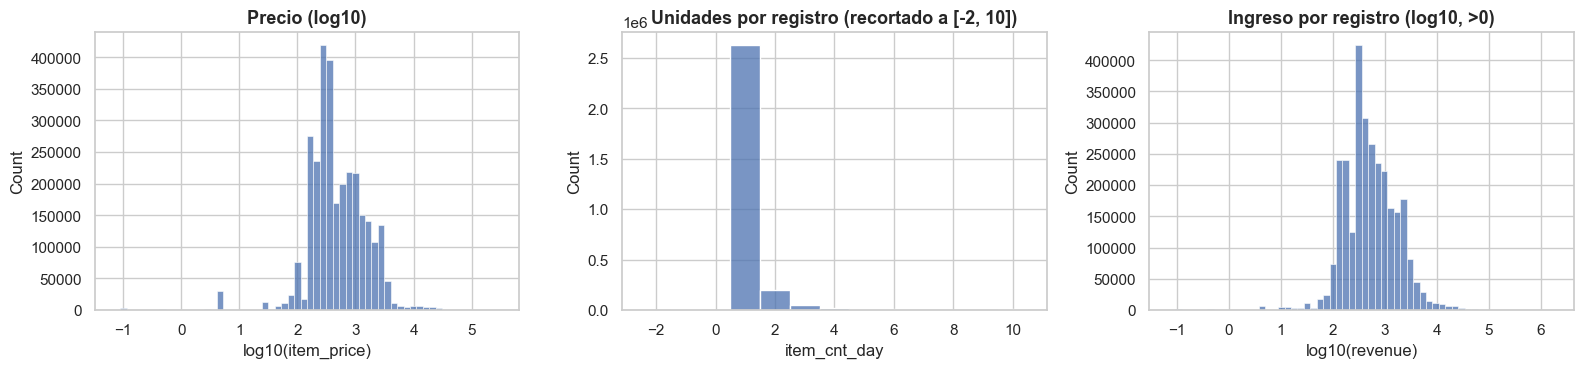

In [130]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(np.log10(df.loc[df["item_price"] > 0, "item_price"]), bins=60, ax=axes[0])
axes[0].set(title="Precio (log10)", xlabel="log10(item_price)")
sns.histplot(df["item_cnt_day"].clip(-2, 10), bins=13, discrete=True, ax=axes[1])
axes[1].set(title="Unidades por registro (recortado a [-2, 10])", xlabel="item_cnt_day")
sns.histplot(np.log10(df.loc[df["revenue"] > 0, "revenue"]), bins=60, ax=axes[2])
axes[2].set(title="Ingreso por registro (log10, >0)", xlabel="log10(revenue)")
plt.tight_layout(); savefig("05a_distribuciones"); plt.show()

En escala logarítmica el precio y el ingreso se ven aproximadamente normales (log‑normales), con picos en precios
"redondos" típicos del retail (299, 399, 999…). Las unidades por registro están concentradas en 1.

### 5.b Distribución de ventas
#### i. Por producto y categoría

In [131]:
por_item = df.groupby("item_id").agg(unidades=("item_cnt_day", "sum"), ingreso=("revenue", "sum"))
print(f"Productos con al menos una venta: {len(por_item):,} de {len(items):,} en el catálogo")
print(por_item["unidades"].describe(percentiles=[.25, .5, .75, .9, .99]).round(1).to_string())

# Concentración: ¿qué % de productos explica el 80 % de las unidades?
acum = por_item["unidades"].sort_values(ascending=False).cumsum() / por_item["unidades"].sum()
print(f"\nEl {100 * (acum <= 0.8).mean():.1f} % de los productos explica el 80 % de las unidades vendidas.")

Productos con al menos una venta: 21,807 de 22,170 en el catálogo
count    21,807.00
mean        167.30
std       1,366.20
min         -11.00
25%           7.00
50%          33.00
75%         124.00
90%         360.00
99%       1,991.80
max     187,642.00

El 17.8 % de los productos explica el 80 % de las unidades vendidas.


In [132]:
por_tipo = (df.groupby("cat_type_es")
              .agg(unidades=("item_cnt_day", "sum"), ingreso=("revenue", "sum"),
                   productos=("item_id", "nunique"), precio_mediano=("item_price", "median"))
              .sort_values("unidades", ascending=False))
por_tipo["% unidades"] = 100 * por_tipo["unidades"] / por_tipo["unidades"].sum()
por_tipo["% ingreso"] = 100 * por_tipo["ingreso"] / por_tipo["ingreso"].sum()
por_tipo

,unidades,ingreso,productos,precio_mediano,% unidades,% ingreso
cat_type_es,,,,,,
Juegos,"1,335,990.00","1,631,849,976.10",3871,799.00,36.62,48.01
Cine,"916,941.00","334,987,320.19",7390,299.00,25.13,9.86
Regalos,"584,366.00","309,146,571.48",3461,569.00,16.02,9.10
Música,"411,294.00","149,719,998.79",4259,299.00,11.27,4.40
Accesorios,"85,056.00","166,386,781.45",217,"1,790.00",2.33,4.90
Libros,"76,341.00","30,348,897.24",1229,299.00,2.09,0.89
Programas,"74,954.00","122,390,895.13",1134,"1,190.00",2.05,3.60
Tarjetas de pago,"53,883.00","72,953,095.72",41,"1,049.00",1.48,2.15
Consolas,"32,155.00","528,028,109.44",144,"13,990.00",0.88,15.54


#### ii. Por sucursal

In [133]:
por_tienda = (df.groupby(["shop_id", "shop_name", "city"])
                .agg(unidades=("item_cnt_day", "sum"), ingreso=("revenue", "sum"),
                     meses_activos=("date_block_num", "nunique"), productos=("item_id", "nunique"))
                .reset_index().sort_values("unidades", ascending=False))
por_tienda["unidades_por_mes"] = por_tienda["unidades"] / por_tienda["meses_activos"]
print(por_tienda[["unidades", "unidades_por_mes"]].describe().round(0).to_string())
por_tienda.head(10)

        unidades  unidades_por_mes
count      57.00             57.00
mean   64,004.00          2,168.00
std    58,419.00          1,672.00
min       330.00            330.00
25%    25,838.00          1,292.00
50%    53,886.00          1,879.00
75%    71,201.00          2,242.00
max   310,777.00          9,140.00


,shop_id,shop_name,city,unidades,ingreso,meses_activos,productos,unidades_por_mes
28,31,"Москва ТЦ ""Семеновский""",Москва,"310,777.00","235,217,019.05",34,14416,"9,140.50"
22,25,"Москва ТРК ""Атриум""",Москва,"241,919.00","216,479,572.44",34,15367,"7,115.26"
51,54,"Химки ТЦ ""Мега""",Химки,"185,789.00","141,939,524.00",28,13863,"6,635.32"
25,28,"Москва ТЦ ""МЕГА Теплый Стан"" II",Москва,"184,557.00","159,746,337.38",34,12572,"5,428.15"
54,57,"Якутск Орджоникидзе, 56",Якутск,"152,812.00","119,637,153.53",34,12815,"4,494.47"
39,42,"СПб ТК ""Невский Центр""",СПб,"144,933.00","151,916,533.55",34,12034,"4,262.74"
24,27,"Москва ТЦ ""МЕГА Белая Дача II""",Москва,"136,657.00","140,632,474.12",32,10842,"4,270.53"
4,6,"Воронеж (Плехановская, 13)",Воронеж,"100,489.00","98,067,453.80",34,11856,"2,955.56"
55,58,"Якутск ТЦ ""Центральный""",Якутск,"88,045.00","71,975,824.83",34,9086,"2,589.56"
43,46,"Сергиев Посад ТЦ ""7Я""",Сергиев,"78,990.00","74,189,318.92",34,9149,"2,323.24"


In [134]:
por_ciudad = df.groupby("city").agg(unidades=("item_cnt_day", "sum"), tiendas=("shop_id", "nunique"))
por_ciudad["%"] = 100 * por_ciudad["unidades"] / por_ciudad["unidades"].sum()
por_ciudad.sort_values("unidades", ascending=False).head(10)

,unidades,tiendas,%
city,,,
Москва,"1,276,374.00",13,34.99
Якутск,"240,857.00",2,6.60
СПб,"195,541.00",2,5.36
Химки,"185,789.00",1,5.09
Воронеж,"171,142.00",3,4.69
Тюмень,"142,093.00",3,3.89
Уфа,"111,401.00",2,3.05
Красноярск,"91,324.00",2,2.50
Самара,"86,833.00",2,2.38


#### iii. Por periodo de tiempo (día, semana, mes, año)

In [135]:
diaria = df.groupby("date").agg(unidades=("item_cnt_day", "sum"), ingreso=("revenue", "sum"))
semanal = diaria.resample("W-SUN").sum().iloc[1:-1]    # quitamos semanas incompletas en los extremos
mensual = df.groupby("date_block_num").agg(unidades=("item_cnt_day", "sum"), ingreso=("revenue", "sum"))
mensual.index = pd.period_range("2013-01", periods=len(mensual), freq="M")

anual = df[df["month"] <= 10].groupby("year").agg(unidades=("item_cnt_day", "sum"), ingreso=("revenue", "sum"))
anual["var_% unidades"] = 100 * anual["unidades"].pct_change()
anual["var_% ingreso"] = 100 * anual["ingreso"].pct_change()

resumen = pd.DataFrame({
    "media": [diaria["unidades"].mean(), semanal["unidades"].mean(), mensual["unidades"].mean()],
    "mediana": [diaria["unidades"].median(), semanal["unidades"].median(), mensual["unidades"].median()],
    "min": [diaria["unidades"].min(), semanal["unidades"].min(), mensual["unidades"].min()],
    "max": [diaria["unidades"].max(), semanal["unidades"].max(), mensual["unidades"].max()],
    "std": [diaria["unidades"].std(), semanal["unidades"].std(), mensual["unidades"].std()]},
    index=["diaria", "semanal", "mensual"])
display(resumen)
print("Comparación anual (solo enero–octubre para que los años sean comparables):")
anual

,media,mediana,min,max,std
diaria,"3,528.24","3,145.00","1,274.00","13,343.00","1,584.68"
semanal,"24,645.97","24,500.50","12,389.00","57,680.00","7,801.24"
mensual,"107,300.00","107,306.00","63,187.00","183,342.00","28,455.95"


Comparación anual (solo enero–octubre para que los años sean comparables):


,unidades,ingreso,var_% unidades,var_% ingreso
year,,,,
2013,"1,249,381.00","871,289,289.22",NaN,NaN
2014,"1,034,285.00","962,711,712.66",-17.22,10.49
2015,"764,584.00","834,623,131.78",-26.08,-13.30


**Interpretación de 5.b:** (ver comentarios detallados en las secciones 6 y 7)
- Las ventas están **muy concentradas**: pocos productos y pocas categorías explican la mayor parte del volumen.
- Comparando enero–octubre, las **unidades caen año con año**, mientras que el **ingreso cae mucho menos** (o
  incluso crece) → el ticket promedio sube: se venden menos unidades pero más caras (consolas y juegos de nueva
  generación como PS4/Xbox One).

## 6. Exploración temporal
### 6.a Evolución de las ventas

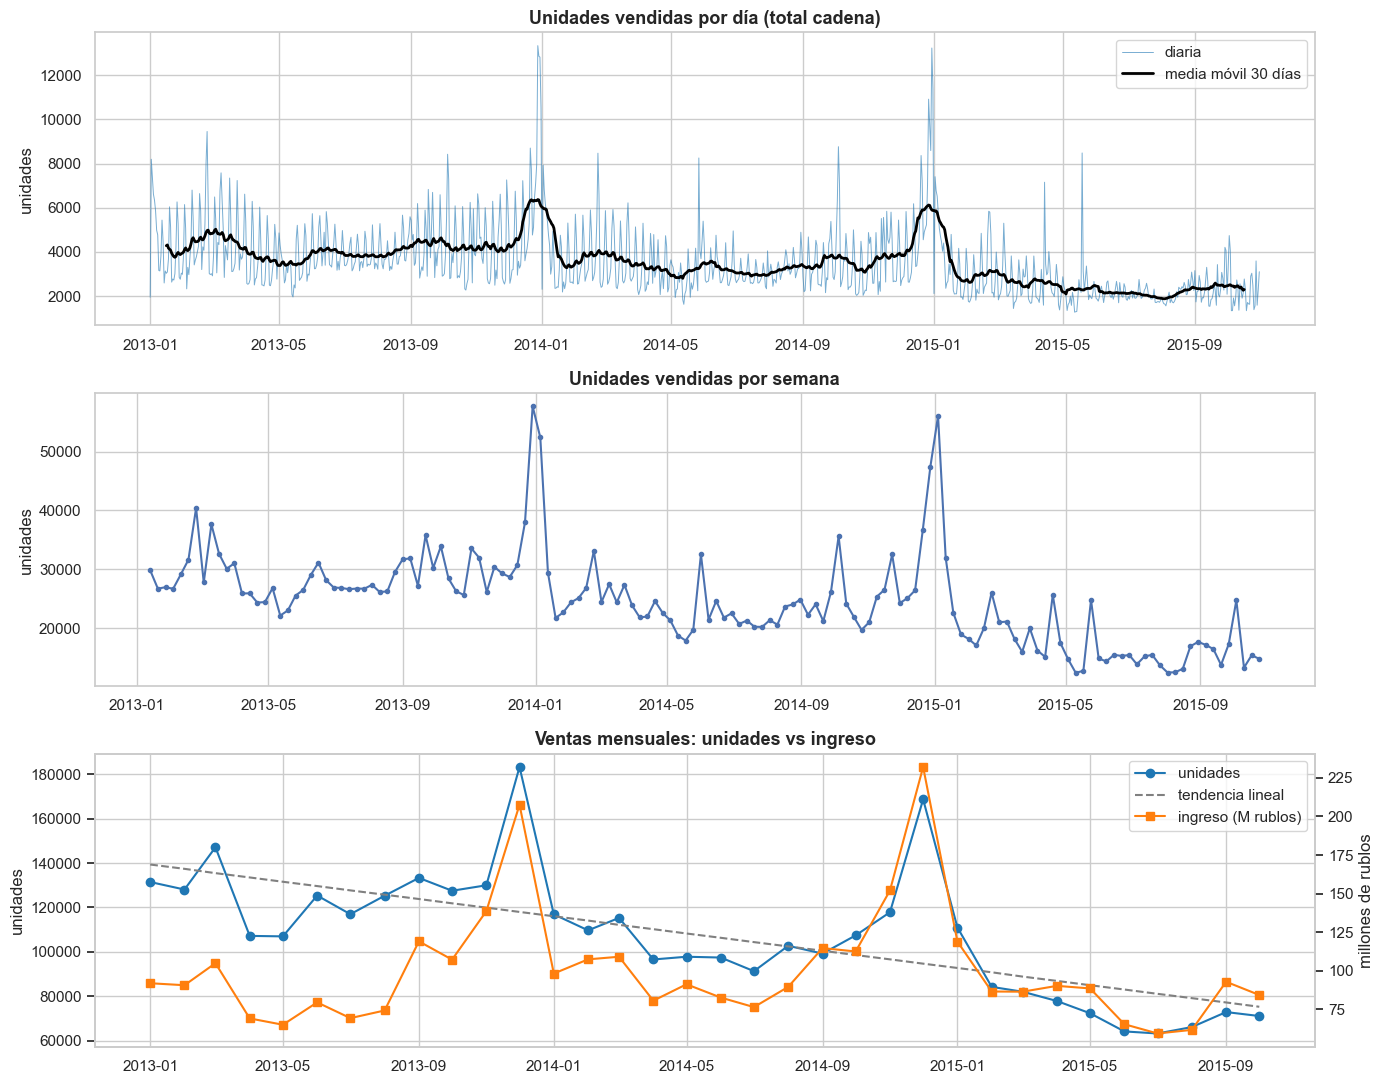

Pendiente de la tendencia lineal: -1,944 unidades/mes


In [136]:
fig, axes = plt.subplots(3, 1, figsize=(14, 11))
axes[0].plot(diaria.index, diaria["unidades"], lw=0.7, color="tab:blue", alpha=0.6, label="diaria")
axes[0].plot(diaria.index, diaria["unidades"].rolling(30, center=True).mean(), color="black", lw=2,
             label="media móvil 30 días")
axes[0].set(title="Unidades vendidas por día (total cadena)", ylabel="unidades"); axes[0].legend()

axes[1].plot(semanal.index, semanal["unidades"], marker="o", ms=3)
axes[1].set(title="Unidades vendidas por semana", ylabel="unidades")

x = mensual.index.to_timestamp()
axes[2].plot(x, mensual["unidades"], marker="o", color="tab:blue", label="unidades")
ax2 = axes[2].twinx()
ax2.plot(x, mensual["ingreso"] / 1e6, marker="s", color="tab:orange", label="ingreso (M rublos)")
z = np.polyfit(np.arange(len(mensual)), mensual["unidades"], 1)
axes[2].plot(x, np.polyval(z, np.arange(len(mensual))), "--", color="gray", label="tendencia lineal")
axes[2].set(title="Ventas mensuales: unidades vs ingreso", ylabel="unidades")
ax2.set_ylabel("millones de rublos"); ax2.grid(False)
h1, l1 = axes[2].get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
axes[2].legend(h1 + h2, l1 + l2, loc="upper right")
plt.tight_layout(); savefig("06a_evolucion_ventas"); plt.show()
print(f"Pendiente de la tendencia lineal: {z[0]:,.0f} unidades/mes")

### 6.b Patrones: tendencia, estacionalidad, picos y ciclos

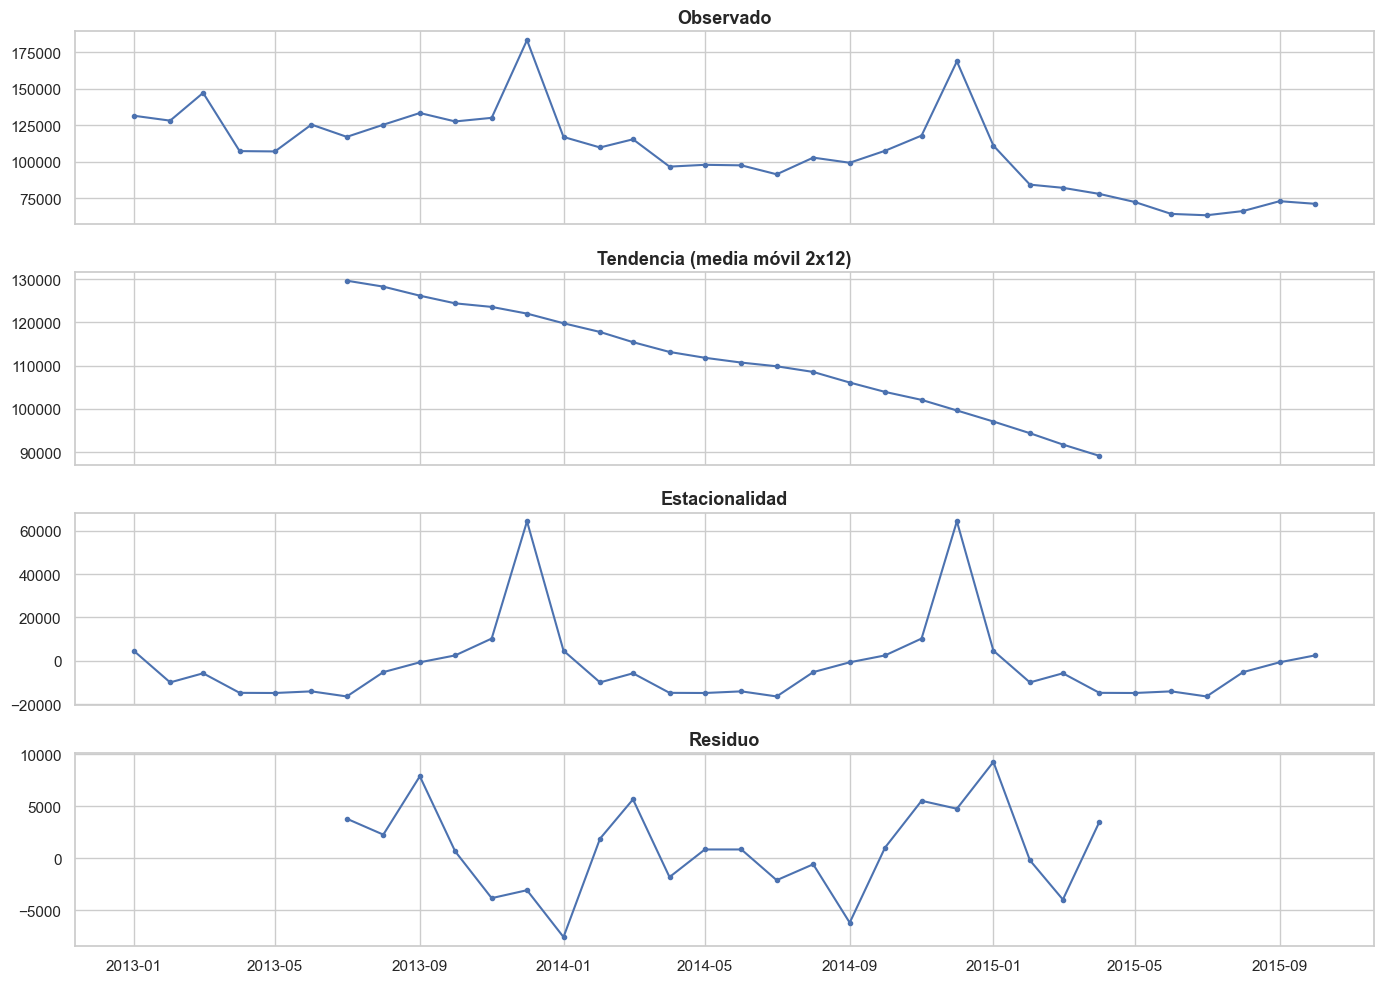

Índice estacional (unidades sobre/bajo la tendencia):
Ene     4,674.00
Feb    -9,965.00
Mar    -5,758.00
Abr   -14,785.00
May   -14,856.00
Jun   -14,101.00
Jul   -16,449.00
Ago    -5,224.00
Sep      -689.00
Oct     2,491.00
Nov    10,271.00
Dic    64,390.00


In [137]:
# Descomposición clásica aditiva (implementación propia): tendencia = media móvil centrada 2x12
u = mensual["unidades"].astype(float).values
trend = pd.Series(u).rolling(12, center=True).mean().rolling(2).mean().shift(-1).values
detr = u - trend
mes_cal = np.arange(len(u)) % 12
seasonal_idx = pd.Series(detr).groupby(mes_cal).mean()
seasonal_idx -= seasonal_idx.mean()
seasonal = seasonal_idx.values[mes_cal]
resid = u - trend - seasonal

fig, axes = plt.subplots(4, 1, figsize=(14, 10), sharex=True)
for ax, serie, t in zip(axes, [u, trend, seasonal, resid],
                        ["Observado", "Tendencia (media móvil 2x12)", "Estacionalidad", "Residuo"]):
    ax.plot(x, serie, marker="o", ms=3); ax.set_title(t)
plt.tight_layout(); savefig("06b_descomposicion"); plt.show()

meses_nombre = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]
print("Índice estacional (unidades sobre/bajo la tendencia):")
print(pd.Series(seasonal_idx.values.round(0), index=meses_nombre).to_string())

In [138]:
# Picos y caídas abruptas: variación mes contra mes
mom = mensual["unidades"].pct_change() * 100
print("Mayores subidas mes a mes (%):"); print(mom.nlargest(4).round(1).to_string())
print("\nMayores caídas mes a mes (%):"); print(mom.nsmallest(4).round(1).to_string())

# Días con más ventas
print("\nTop 8 días con más unidades vendidas:")
top_dias = diaria["unidades"].nlargest(8)
print(pd.DataFrame({"unidades": top_dias, "día": top_dias.index.day_name()}).to_string())

Mayores subidas mes a mes (%):
2014-12   43.20
2013-12   41.00
2013-06   17.20
2013-03   14.90
Freq: M

Mayores caídas mes a mes (%):
2014-01   -36.20
2015-01   -34.20
2013-04   -27.20
2015-02   -24.10
Freq: M

Top 8 días con más unidades vendidas:
            unidades        día
date                           
2013-12-28 13,343.00   Saturday
2014-12-30 13,236.00    Tuesday
2013-12-29 12,863.00     Sunday
2013-12-30 12,823.00     Monday
2014-12-31 11,393.00  Wednesday
2014-12-27 10,919.00   Saturday
2013-12-31 10,514.00    Tuesday
2014-12-28  9,727.00     Sunday


#### iv. Ciclos por día de la semana y mes del año

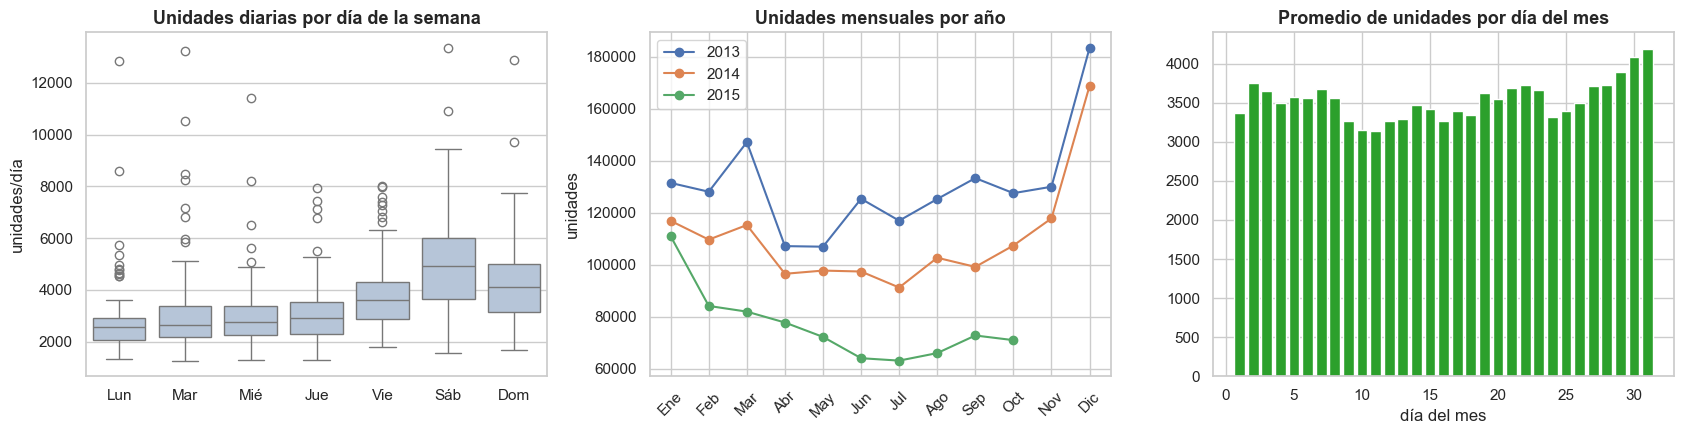

Índice por día de la semana (100 = promedio):
Lun    77.40
Mar    87.10
Mié    84.20
Jue    87.10
Vie   106.00
Sáb   140.70
Dom   117.50


In [139]:
dias_es = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]
prom_dow = diaria.groupby(diaria.index.dayofweek)["unidades"].mean()
idx_dow = 100 * prom_dow / prom_dow.mean()

mens_df = mensual.copy(); mens_df["anio"] = mens_df.index.year; mens_df["mes"] = mens_df.index.month

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
sns.boxplot(x=diaria.index.dayofweek, y=diaria["unidades"], ax=axes[0], color="lightsteelblue")
axes[0].set_xticks(range(7)); axes[0].set_xticklabels(dias_es)
axes[0].set(title="Unidades diarias por día de la semana", xlabel="", ylabel="unidades/día")

for anio, g in mens_df.groupby("anio"):
    axes[1].plot(g["mes"], g["unidades"], marker="o", label=anio)
axes[1].set_xticks(range(1, 13)); axes[1].set_xticklabels(meses_nombre, rotation=45)
axes[1].set(title="Unidades mensuales por año", ylabel="unidades"); axes[1].legend()

prom_dia_mes = diaria.groupby(diaria.index.day)["unidades"].mean()
axes[2].bar(prom_dia_mes.index, prom_dia_mes.values, color="tab:green")
axes[2].set(title="Promedio de unidades por día del mes", xlabel="día del mes")
plt.tight_layout(); savefig("06b_ciclos"); plt.show()

print("Índice por día de la semana (100 = promedio):")
print(pd.Series(idx_dow.values.round(1), index=dias_es).to_string())

**Interpretación de la sección 6:**

**i. Tendencia — decreciente.** Las unidades caen ≈ 1,944 por mes (tendencia lineal). Comparando enero‑octubre:
1.25 M (2013) → 1.03 M (2014, −17 %) → 0.76 M (2015, −26 %). El **ingreso** subió 10.5 % en 2014 y cayó 13 % en 2015:
el ticket promedio aumenta (consolas y juegos PS4/Xbox One son más caros), mientras que el volumen físico se
reduce, en parte por el paso de formatos físicos (DVD, CD) a digital y por la crisis del rublo de fines de 2014.

**ii. Estacionalidad — anual, muy marcada en diciembre.** Diciembre está ≈ 64 mil unidades por encima de la
tendencia (temporada de Año Nuevo, la principal fiesta de regalos en Rusia); noviembre también está arriba. Abril–julio
son los meses más débiles (≈ −15 mil). Enero queda ligeramente arriba de la tendencia por los primeros días de
vacaciones de Año Nuevo.

**iii. Picos y caídas abruptas.** Las mayores subidas son dic‑2014 (+43 %) y dic‑2013 (+41 %); las caídas más
fuertes son justo después: ene‑2014 (−36 %) y ene‑2015 (−34 %). Los 8 días con más ventas del período son **27–31 de
diciembre**. También hay picos aislados de un día en la serie diaria que coinciden con lanzamientos de videojuegos
(p. ej. mar‑2013 con *StarCraft II: Heart of the Swarm*, sep‑2013 con *GTA V*). En sep‑2015 el ingreso sube por la
venta masiva de boletos para la feria ИгроМир (ver 7.c).

**iv. Ciclos semanales y mensuales.**
- **Día de la semana:** sábado es el día fuerte (índice 141), seguido de domingo (118) y viernes (106); el lunes es el
  más débil (77). Es el comportamiento típico de tiendas en centros comerciales. Esto solo importa si se modela a nivel
  diario; al agregar por mes, el **número de fines de semana del mes** puede usarse como variable.
- **Mes del año:** los tres años muestran la misma forma (caída en primavera‑verano, subida en otoño y pico en
  diciembre), solo que cada año está más abajo.
- **Día del mes:** el promedio sube hacia el final del mes (días 27–31), influido sobre todo por las compras de fin de
  año en diciembre.

## 7. Análisis comparativo entre sucursales y productos
### 7.a Productos y categorías más y menos vendidos

In [140]:
nombres = items.set_index("item_id")["item_name"]
por_item = por_item.join(nombres).join(items.set_index("item_id")["item_category_id"])
por_item = por_item.join(categories.set_index("item_category_id")[["item_category_name"]], on="item_category_id")

print("TOP 10 productos por unidades:")
display(por_item.nlargest(10, "unidades")[["item_name", "item_category_name", "unidades", "ingreso"]])
print("TOP 10 productos por ingreso:")
display(por_item.nlargest(10, "ingreso")[["item_name", "item_category_name", "unidades", "ingreso"]])

TOP 10 productos por unidades:


,item_name,item_category_name,unidades,ingreso
item_id,,,,
20949,Фирменный пакет майка 1С Интерес белый (34*42)...,"Подарки - Сумки, Альбомы, Коврики д/мыши","187,642.00","928,863.70"
2808,"Diablo III [PC, Jewel, русская версия]",Игры PC - Стандартные издания,"17,245.00","16,852,778.42"
3732,"Grand Theft Auto V [PS3, русские субтитры]",Игры - PS3,"16,642.00","43,617,975.48"
17717,Прием денежных средств для 1С-Онлайн,Служебные,"15,830.00","17,200,825.93"
5822,Playstation Store пополнение бумажника: Карта ...,Карты оплаты - PSN,"14,515.00","15,408,983.12"
3734,"Grand Theft Auto V [Xbox 360, русские субтитры]",Игры - XBOX 360,"11,688.00","31,065,160.27"
6675,Sony PlayStation 4 (500 Gb) Black (CUH-1008A/1...,Игровые консоли - PS4,"10,289.00","219,391,488.92"
3731,"Grand Theft Auto V [PC, русские субтитры]",Игры PC - Стандартные издания,"10,099.00","19,983,482.89"
1855,"Battlefield 4 [PC, русская версия]",Игры PC - Стандартные издания,"10,032.00","9,357,024.78"


TOP 10 productos por ingreso:


,item_name,item_category_name,unidades,ingreso
item_id,,,,
6675,Sony PlayStation 4 (500 Gb) Black (CUH-1008A/1...,Игровые консоли - PS4,"10,289.00","219,391,488.92"
3732,"Grand Theft Auto V [PS3, русские субтитры]",Игры - PS3,"16,642.00","43,617,975.48"
13443,Комплект Sony PS4 (500 Gb) Black (CUH-1108A/B0...,Игровые консоли - PS4,"1,366.00","34,331,245.28"
3734,"Grand Theft Auto V [Xbox 360, русские субтитры]",Игры - XBOX 360,"11,688.00","31,065,160.27"
3733,"Grand Theft Auto V [PS4, русские субтитры]",Игры - PS4,"6,506.00","22,298,864.36"
16787,"Одни из нас [PS3, русская версия]",Игры - PS3,"9,227.00","21,907,839.08"
3731,"Grand Theft Auto V [PC, русские субтитры]",Игры PC - Стандартные издания,"10,099.00","19,983,482.89"
13405,"Комплект ""Microsoft Xbox One 500GB (Day One Ed...",Игровые консоли - XBOX ONE,991.00,"18,125,479.52"
17717,Прием денежных средств для 1С-Онлайн,Служебные,"15,830.00","17,200,825.93"


In [141]:
print("Productos con ventas netas <= 0 (más devoluciones que ventas):", (por_item["unidades"] <= 0).sum())
print("Productos que vendieron exactamente 1 unidad en todo el período:", (por_item["unidades"] == 1).sum())
print(f"Productos del catálogo sin ninguna venta en train: {len(items) - len(por_item):,}")
print("\nBOTTOM 10 productos (unidades netas):")
por_item.nsmallest(10, "unidades")[["item_name", "item_category_name", "unidades", "ingreso"]]

Productos con ventas netas <= 0 (más devoluciones que ventas): 8
Productos que vendieron exactamente 1 unidad en todo el período: 2319
Productos del catálogo sin ninguna venta en train: 363

BOTTOM 10 productos (unidades netas):


,item_name,item_category_name,unidades,ingreso
item_id,,,,
1590,"Assassin’s Creed 3. Freedom Edition [PC, русск...",Игры PC - Коллекционные издания,-11.00,"-28,589.00"
11871,Змея,"Подарки - Гаджеты, роботы, спорт",-1.00,"-5,999.00"
13474,Комплект «Sony PS3 (320 Gb) (CECH-2508B) + игр...,Игровые консоли - PS3,-1.00,"-10,398.00"
18062,Робопет Собака,"Подарки - Гаджеты, роботы, спорт",-1.00,"-4,999.00"
4591,"MCCARTNEY, PAUL In Red Square (Фирм.)",Музыка - Музыкальное видео,0.00,0.00
7547,VideoStudio Pro X6 IE Windows Mini-Box,Программы - Для дома и офиса,0.00,0.00
8515,Английский язык. 2 - 5 класс (Jewel),Программы - Обучающие,0.00,14.90
13477,Комплект «Sony PS3 (320 Gb) (CECH-3008B)» + иг...,Игровые консоли - PS3,0.00,"-7,592.00"
0,! ВО ВЛАСТИ НАВАЖДЕНИЯ (ПЛАСТ.) D,Кино - DVD,1.00,58.00


In [142]:
por_cat = (df.groupby(["item_category_id", "item_category_name"])
             .agg(unidades=("item_cnt_day", "sum"), ingreso=("revenue", "sum"))
             .reset_index().sort_values("unidades", ascending=False))
print("TOP 10 categorías por unidades:"); display(por_cat.head(10))
print("BOTTOM 10 categorías por unidades:"); por_cat.tail(10)

TOP 10 categorías por unidades:


,item_category_id,item_category_name,unidades,ingreso
40,40,Кино - DVD,"634,170.00","169,944,072.69"
30,30,Игры PC - Стандартные издания,"456,540.00","257,519,291.08"
55,55,Музыка - CD локального производства,"348,591.00","100,022,563.57"
19,19,Игры - PS3,"254,887.00","412,052,155.90"
37,37,Кино - Blu-Ray,"203,283.00","90,478,232.84"
71,71,"Подарки - Сумки, Альбомы, Коврики д/мыши","187,998.00","934,206.61"
28,28,Игры PC - Дополнительные издания,"174,954.00","136,419,148.64"
23,23,Игры - XBOX 360,"169,940.00","259,615,132.35"
20,20,Игры - PS4,"127,319.00","373,010,312.01"
65,65,Подарки - Настольные игры (компактные),"73,077.00","24,727,890.56"


BOTTOM 10 categorías por unidades:


,item_category_id,item_category_name,unidades,ingreso
18,18,Игры - PS2,11.00,"3,828.20"
27,27,Игры MAC - Цифра,8.00,"5,422.00"
48,48,Книги - Компьютерная литература,6.00,"1,654.00"
53,53,Книги - Художественная литература,3.00,847.00
52,52,Книги - Путеводители,3.00,300.00
50,50,Книги - Открытки,3.00,58.00
0,0,PC - Гарнитуры/Наушники,3.00,263.40
1,1,Аксессуары - PS2,2.00,431.00
10,10,Игровые консоли - PS2,1.00,"1,998.00"
51,51,Книги - Познавательная литература,1.00,129.00


### 7.b Desempeño entre sucursales

In [143]:
tienda_mes = df.groupby(["shop_id", "date_block_num"])["item_cnt_day"].sum().unstack(fill_value=0)
ult6 = tienda_mes.loc[:, 28:33].sum(axis=1)
ant6 = tienda_mes.loc[:, 16:21].sum(axis=1)      # mismos meses (may–oct) del año anterior
comp = por_tienda.set_index("shop_id")[["shop_name", "city", "unidades", "ingreso", "meses_activos",
                                        "unidades_por_mes"]].copy()
comp["ticket_medio"] = comp["ingreso"] / comp["unidades"]
comp["var_% may-oct 15 vs 14"] = 100 * (ult6 / ant6.replace(0, np.nan) - 1)
comp["activa_oct15"] = tienda_mes[33] > 0
comp["en_test"] = comp.index.isin(test["shop_id"])
comp.sort_values("unidades", ascending=False).head(12)

,shop_name,city,unidades,ingreso,meses_activos,unidades_por_mes,ticket_medio,var_% may-oct 15 vs 14,activa_oct15,en_test
shop_id,,,,,,,,,,
31,"Москва ТЦ ""Семеновский""",Москва,"310,777.00","235,217,019.05",34,"9,140.50",756.87,-23.12,True,True
25,"Москва ТРК ""Атриум""",Москва,"241,919.00","216,479,572.44",34,"7,115.26",894.84,-11.54,True,True
54,"Химки ТЦ ""Мега""",Химки,"185,789.00","141,939,524.00",28,"6,635.32",763.98,-100.00,False,False
28,"Москва ТЦ ""МЕГА Теплый Стан"" II",Москва,"184,557.00","159,746,337.38",34,"5,428.15",865.57,-29.88,True,True
57,"Якутск Орджоникидзе, 56",Якутск,"152,812.00","119,637,153.53",34,"4,494.47",782.90,-36.18,True,True
42,"СПб ТК ""Невский Центр""",СПб,"144,933.00","151,916,533.55",34,"4,262.74","1,048.18",7.92,True,True
27,"Москва ТЦ ""МЕГА Белая Дача II""",Москва,"136,657.00","140,632,474.12",32,"4,270.53","1,029.09",-61.60,False,False
6,"Воронеж (Плехановская, 13)",Воронеж,"100,489.00","98,067,453.80",34,"2,955.56",975.90,-37.37,True,True
58,"Якутск ТЦ ""Центральный""",Якутск,"88,045.00","71,975,824.83",34,"2,589.56",817.49,-31.49,True,True


In [144]:
print("Tiendas activas en octubre 2015:", comp["activa_oct15"].sum())
print("Tiendas en test:", test["shop_id"].nunique(), "| ¿todas activas en oct-2015?",
      comp.loc[comp["en_test"], "activa_oct15"].all())
print("Tiendas de evento 9 y 20 con ventas en oct-2015:", comp.loc[[9, 20], "activa_oct15"].tolist(),
      "| ¿están en test?", comp.loc[[9, 20], "en_test"].tolist())
print("\nTiendas que dejaron de vender antes de oct-2015 (cerradas):")
comp.loc[~comp["activa_oct15"], ["shop_name", "meses_activos", "unidades"]]

Tiendas activas en octubre 2015: 44
Tiendas en test: 42 | ¿todas activas en oct-2015? True
Tiendas de evento 9 y 20 con ventas en oct-2015: [True, True] | ¿están en test? [False, False]

Tiendas que dejaron de vender antes de oct-2015 (cerradas):


,shop_name,meses_activos,unidades
shop_id,,,
54,"Химки ТЦ ""Мега""",28,"185,789.00"
27,"Москва ТЦ ""МЕГА Белая Дача II""",32,"136,657.00"
30,"Москва ТЦ ""Перловский""",26,"60,828.00"
29,"Москва ТЦ ""Новый век"" (Новокосино)",29,"58,713.00"
43,"СПб ТК ""Сенная""",25,"50,608.00"
51,"Тюмень ТЦ ""Зеленый Берег""",33,"48,767.00"
17,"Красноярск ТЦ ""Взлетка Плаза""",20,"25,838.00"
13,"Казань ТЦ ""Бехетле""",20,"19,763.00"
32,"Москва ТЦ ""Серебряный Дом""",7,"8,781.00"


### 7.c Outliers y comportamientos anómalos

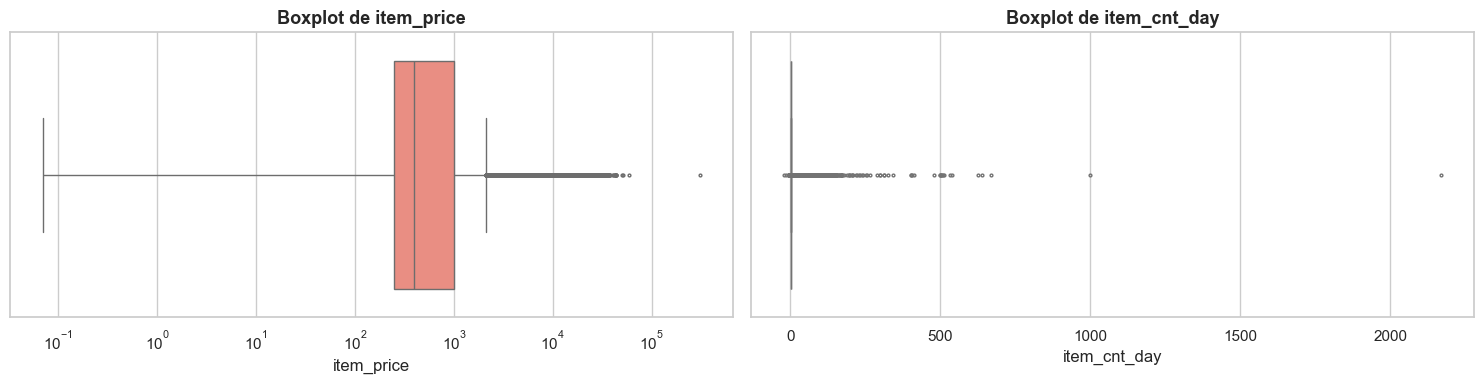

In [145]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
sns.boxplot(x=df["item_price"], ax=axes[0], color="salmon", fliersize=2)
axes[0].set(title="Boxplot de item_price", xscale="log")
sns.boxplot(x=df["item_cnt_day"], ax=axes[1], color="lightgreen", fliersize=2)
axes[1].set(title="Boxplot de item_cnt_day")
plt.tight_layout(); savefig("07c_boxplots_outliers"); plt.show()

In [146]:
cols = ["date", "shop_id", "shop_name", "item_id", "item_category_name", "item_price", "item_cnt_day", "revenue"]
print("Transacciones con precio más alto:")
display(df.nlargest(5, "item_price")[cols].merge(nombres.rename("item_name"), left_on="item_id", right_index=True))
print("Transacciones con más unidades en un día:")
df.nlargest(5, "item_cnt_day")[cols].merge(nombres.rename("item_name"), left_on="item_id", right_index=True)

Transacciones con precio más alto:


,date,shop_id,shop_name,item_id,item_category_name,item_price,item_cnt_day,revenue,item_name
1163157,2013-12-13,12,Интернет-магазин ЧС,6066,Программы - Для дома и офиса,"307,980.00",1.00,"307,980.00",Radmin 3 - 522 лиц.
885137,2013-09-17,12,Интернет-магазин ЧС,11365,Доставка товара,"59,200.00",1.00,"59,200.00",Доставка (EMS)
1488133,2014-03-20,25,"Москва ТРК ""Атриум""",13199,Подарки - Сувениры,"50,999.00",1.00,"50,999.00",Коллекционные шахматы (Властелин Колец)
2327153,2015-01-29,12,Интернет-магазин ЧС,7241,Программы - Для дома и офиса,"49,782.00",1.00,"49,782.00",UserGate Proxy & Firewall 6.X с модулем фильтр...
2885686,2015-10-23,42,"СПб ТК ""Невский Центр""",13403,Игровые консоли - XBOX ONE,"42,990.00",1.00,"42,990.00","Комплект ""Microsoft Xbox One 1TB Limited Edit..."


Transacciones con más unidades en un día:


,date,shop_id,shop_name,item_id,item_category_name,item_price,item_cnt_day,revenue,item_name
2909812,2015-10-28,12,Интернет-магазин ЧС,11373,Доставка товара,0.91,"2,169.00","1,971.00",Доставка до пункта выдачи (Boxberry)
2326924,2015-01-15,12,Интернет-магазин ЧС,20949,"Подарки - Сумки, Альбомы, Коврики д/мыши",4.00,"1,000.00","4,000.00",Фирменный пакет майка 1С Интерес белый (34*42)...
2864229,2015-09-30,12,Интернет-магазин ЧС,9248,Служебные - Билеты,"1,692.53",669.00,"1,132,300.00","Билет ""ИгроМир 2015"" - 3 октября 2015 (сайт) [..."
2851085,2015-09-30,55,Цифровой склад 1С-Онлайн,9249,Билеты (Цифра),"1,702.83",637.00,"1,084,700.00","Билет ""ИгроМир 2015"" - 3 октября 2015 (сайт) У..."
2608034,2015-04-14,12,Интернет-магазин ЧС,3731,Игры PC - Стандартные издания,"1,904.55",624.00,"1,188,438.00","Grand Theft Auto V [PC, русские субтитры]"


In [147]:
# Criterio robusto por producto: z-score usando mediana y MAD del precio de cada producto
med = df.groupby("item_id")["item_price"].transform("median")
mad = df.groupby("item_id")["item_price"].transform(lambda s: (s - s.median()).abs().median())
z_rob = (df["item_price"] - med) / (1.4826 * mad.replace(0, np.nan))
print("Registros con precio > 10 MAD por encima de la mediana de su producto:", int((z_rob > 10).sum()),
      f"({100 * (z_rob > 10).mean():.2f} %)")

# Tiendas con comportamiento anómalo: meses con ventas muy por encima de su mediana
ratio = tienda_mes.div(tienda_mes.replace(0, np.nan).median(axis=1), axis=0)
anom = ratio.stack()
anom = anom[anom > 2.5].sort_values(ascending=False)
print("\nMeses tienda con ventas > 2.5x su mediana mensual:")
print(anom.head(10).round(2).to_string())

Registros con precio > 10 MAD por encima de la mediana de su producto: 18424 (0.63 %)

Meses tienda con ventas > 2.5x su mediana mensual:
shop_id  date_block_num
55       32               4.52
         24               4.23
12       32               2.79
55       21               2.78
40       23               2.74


**Tratamiento de outliers (decisión para el modelado):**
- **`item_price` = 307,980** (1 registro): software corporativo (licencias) con precio fuera de toda proporción;
  se **elimina** el registro (`item_price > 100,000`).
- **`item_cnt_day` = 2,169 y 1,000**: ventas puntuales masivas (envíos/mayoreo) que no representan la demanda
  normal; se **eliminan** los registros con `item_cnt_day > 900`.
- El resto de valores altos (consolas caras, preventas de lanzamientos) **son legítimos** y se conservan.
  Para el modelo, el objetivo mensual se recortará a [0, 20], igual que en la evaluación de Kaggle.

In [148]:
n0 = len(df)
df = df[(df["item_price"] <= 100_000) & (df["item_cnt_day"] <= 900)].copy()
print(f"Outliers eliminados: {n0 - len(df)} → quedan {len(df):,} filas")
print("Bolsa 20949 tras quitar outliers:", df.loc[df["item_id"] == 20949, "item_cnt_day"].sum(), "unidades")
# Recalculamos agregados con los datos limpios
diaria = df.groupby("date").agg(unidades=("item_cnt_day", "sum"), ingreso=("revenue", "sum"))
mensual = df.groupby("date_block_num").agg(unidades=("item_cnt_day", "sum"), ingreso=("revenue", "sum"))
mensual.index = pd.period_range("2013-01", periods=len(mensual), freq="M")

Outliers eliminados: 3 → quedan 2,935,840 filas
Bolsa 20949 tras quitar outliers: 186642.0 unidades


> **Nota sobre el orden de la limpieza:** los 3 outliers se eliminan aquí (7.c), así que las estadísticas de las
> secciones 5 y 6 y los totales de 7.a–7.b se calcularon con ellos incluidos. El efecto es despreciable (3 de 2.9 M
> filas). El cambio más visible es la bolsa 20949, que pasa de 187,642 a 186,642 unidades; el ranking no cambia. Las
> secciones 8, 9 y 10 ya usan los datos sin outliers.

**Interpretación de la sección 7:**

- **Productos.** El producto con más unidades (item 20949, 187,642 unidades) **no es un producto**: es la bolsa con la
  marca de la tienda (precio ≈ 4 rublos). Entre productos reales destacan *Diablo III* (PC), *GTA V* (PS3/Xbox 360/PC)
  y las tarjetas de saldo de PlayStation Store. Por **ingreso**, el líder absoluto es la consola **PS4** (≈ 219 M
  rublos, unas 5 veces más que el segundo, *GTA V* para PS3 con ≈ 43.6 M). La venta está muy concentrada: **17.8 % de los productos explica el 80 % de las
  unidades**, mientras 2,319 productos vendieron una sola unidad en casi 3 años (cola larga).
- **Categorías.** *Кино ‑ DVD* (cine en DVD) es la categoría con más unidades (634 mil), seguida de juegos de PC
  estándar y CD de música local. Por tipo, **Juegos** aporta 37 % de las unidades y 48 % del ingreso; **Consolas**
  apenas 0.9 % de las unidades pero **15.5 % del ingreso**. Las categorías menos vendidas son productos casi
  descontinuados (PS2) y libros de nicho.
- **Sucursales.** El desempeño es muy desigual: la tienda 31 (Moscú, TC "Semenovsky") vende ≈ 9,100 unidades/mes,
  más de 4 veces la mediana (≈ 1,900). Moscú concentra 35 % del volumen con 13 tiendas. **13 tiendas no tienen ventas en oct‑2015 (cerradas)**,
  incluida la 54, la tercera más grande. Hay 44 tiendas activas en oct‑2015: las **42 de test** más las tiendas de
  evento 9 y 20, que venden justo en octubre pero no se piden en test. Casi
  todas venden menos en may‑oct 2015 que en el mismo período de 2014.
- **Comportamientos anómalos.**
  - Tienda **12 (tienda online)** y **55 (almacén digital 1C‑Online)**: concentran las transacciones extremas
    (envíos con precio < 1 rublo y 2,169 unidades, venta masiva de boletos para la feria ИгроМир en sep‑2015,
    ventas al mayoreo). Se comportan distinto a una tienda física.
  - Tiendas **9 ("venta itinerante")** y **20 ("Moscú Remate")**: solo venden en **octubre** (feria ИгроМир);
    ninguna está en test.
  - Tienda **36**: abrió en oct‑2015 (un solo mes de historia) y **sí está en test** → su predicción dependerá de
    variables de ciudad/categoría, no de su propio historial.
  - Precios: 0.63 % de los registros tiene un precio > 10 MAD por encima de la mediana de su producto. Son en su
    mayoría cambios de precio en el tiempo (lanzamiento vs. descuento), no errores, así que se conservan.

## 8. Visualizaciones clave
### 8.a Serie de tiempo de ventas totales

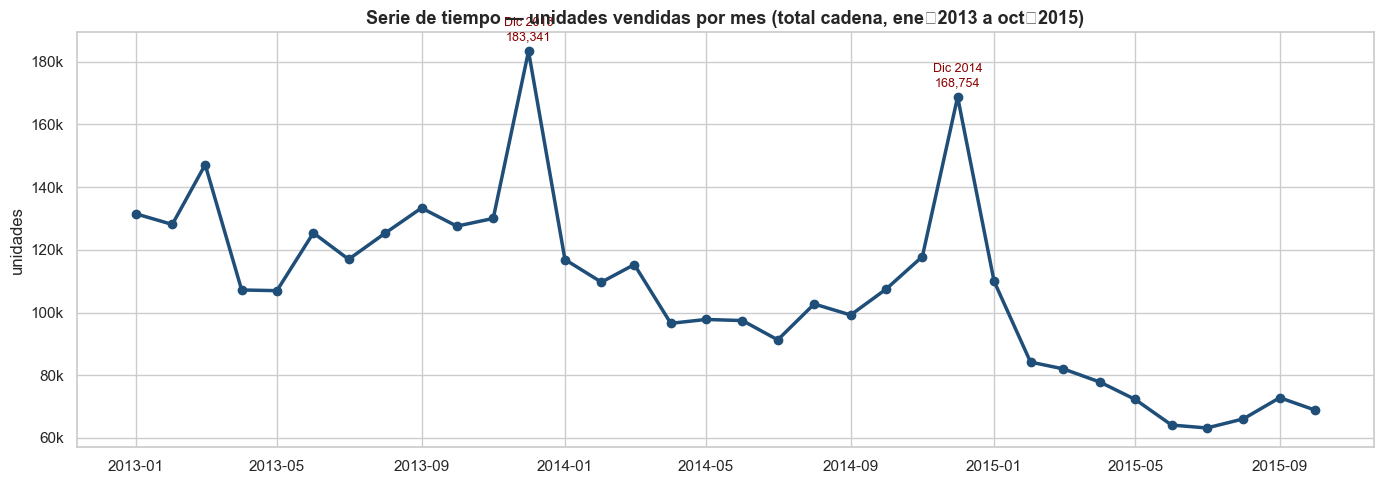

In [149]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(x, mensual["unidades"], marker="o", lw=2.5, color="#1f4e79")
for i, (p, v) in enumerate(mensual["unidades"].items()):
    if p.month == 12:
        ax.annotate(f"Dic {p.year}\n{v:,.0f}", (x[i], v), textcoords="offset points", xytext=(0, 8),
                    ha="center", fontsize=9, color="darkred")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v/1e3:,.0f}k"))
ax.set(title="Serie de tiempo — unidades vendidas por mes (total cadena, ene‑2013 a oct‑2015)",
       ylabel="unidades")
plt.tight_layout(); savefig("08a_serie_total"); plt.show()

### 8.b Ventas por sucursal

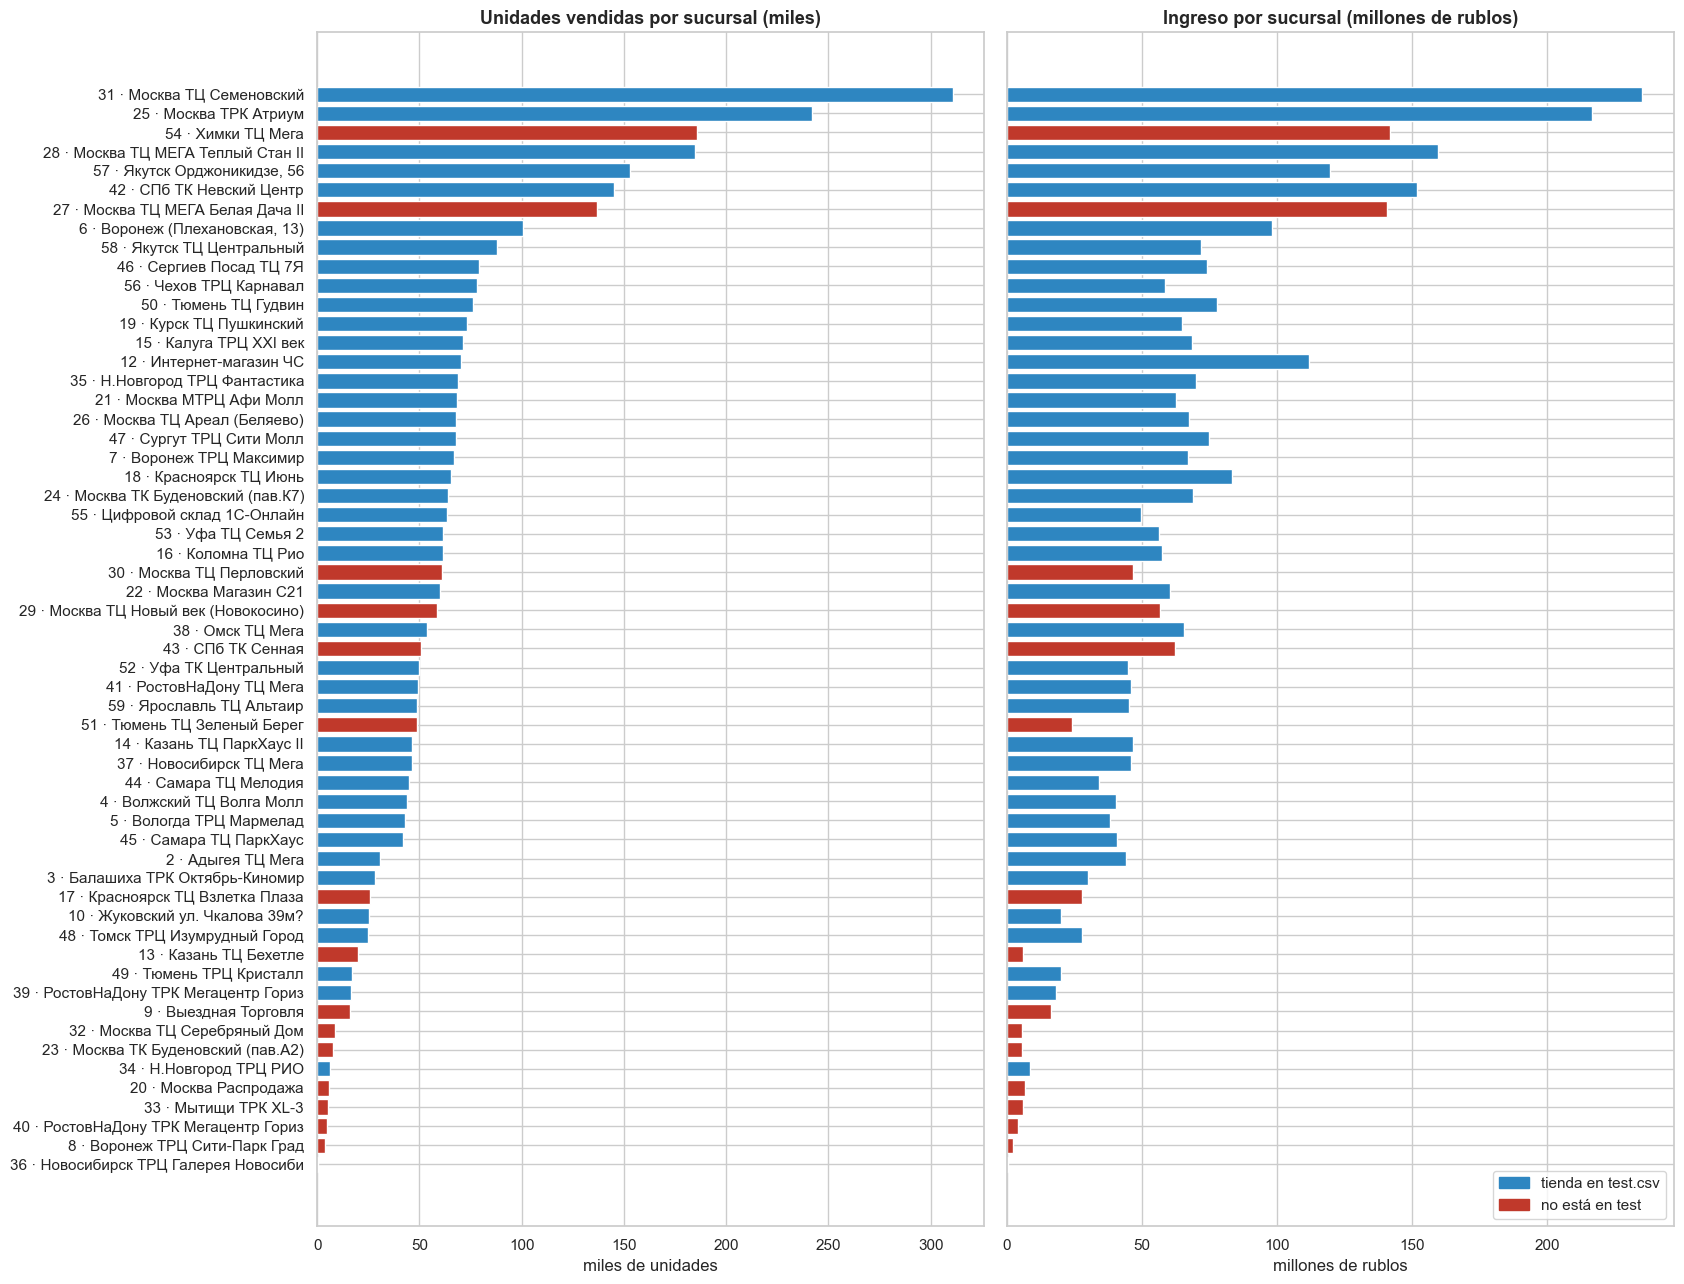

In [150]:
t = df.groupby("shop_id").agg(unidades=("item_cnt_day", "sum"), ingreso=("revenue", "sum"))
t = t.join(shops.set_index("shop_id")["shop_name"]).sort_values("unidades")
t["label"] = t.index.astype(str) + " · " + t["shop_name"].str.replace('"', "").str.slice(0, 32)

fig, axes = plt.subplots(1, 2, figsize=(17, 13), sharey=True)
colores = ["#c0392b" if s not in set(test["shop_id"]) else "#2e86c1" for s in t.index]
axes[0].barh(t["label"], t["unidades"] / 1e3, color=colores)
axes[0].set(title="Unidades vendidas por sucursal (miles)", xlabel="miles de unidades")
axes[1].barh(t["label"], t["ingreso"] / 1e6, color=colores)
axes[1].set(title="Ingreso por sucursal (millones de rublos)", xlabel="millones de rublos")
from matplotlib.patches import Patch
axes[1].legend(handles=[Patch(color="#2e86c1", label="tienda en test.csv"),
                        Patch(color="#c0392b", label="no está en test")], loc="lower right")
plt.tight_layout(); savefig("08b_ventas_sucursal"); plt.show()

### 8.c Ventas por producto (top N) y por categoría

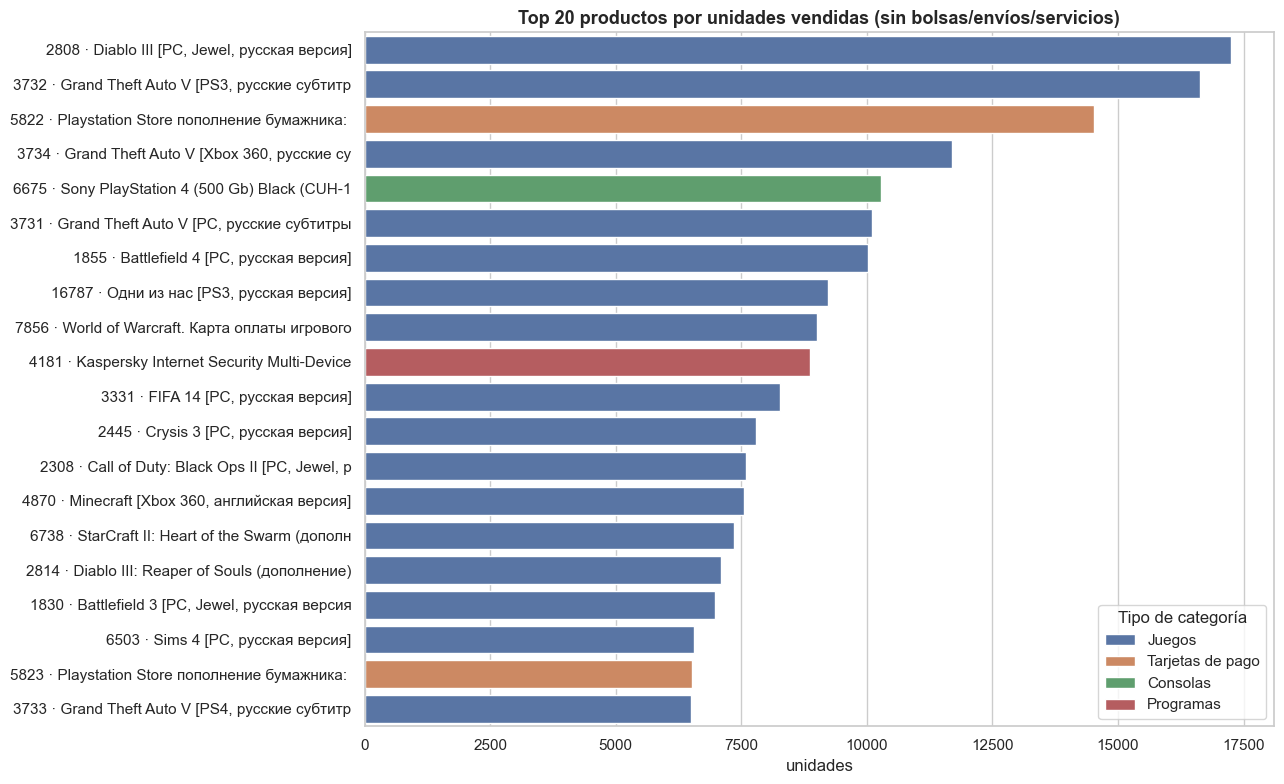

In [151]:
N = 20
# Se excluyen bolsas, envíos y servicios (no son productos): la bolsa 20949 sola tiene 187k unidades
# y aplastaría la escala del gráfico.
NO_PROD_CAT = [8, 9, 71, 79, 80]
es_producto = ~df["item_category_id"].isin(NO_PROD_CAT)
top_items = (df[es_producto].groupby("item_id")["item_cnt_day"].sum().nlargest(N).to_frame("unidades")
               .join(nombres).join(items.set_index("item_id")["item_category_id"]))
top_items = top_items.join(categories.set_index("item_category_id")["cat_type_es"], on="item_category_id")
top_items["label"] = top_items.index.astype(str) + " · " + top_items["item_name"].str.slice(0, 40)

fig, ax = plt.subplots(figsize=(13, 8))
sns.barplot(data=top_items.reset_index(), y="label", x="unidades", hue="cat_type_es", dodge=False, ax=ax)
ax.set(title=f"Top {N} productos por unidades vendidas (sin bolsas/envíos/servicios)", xlabel="unidades", ylabel="")
ax.legend(title="Tipo de categoría", loc="lower right")
plt.tight_layout(); savefig("08c_top_productos"); plt.show()

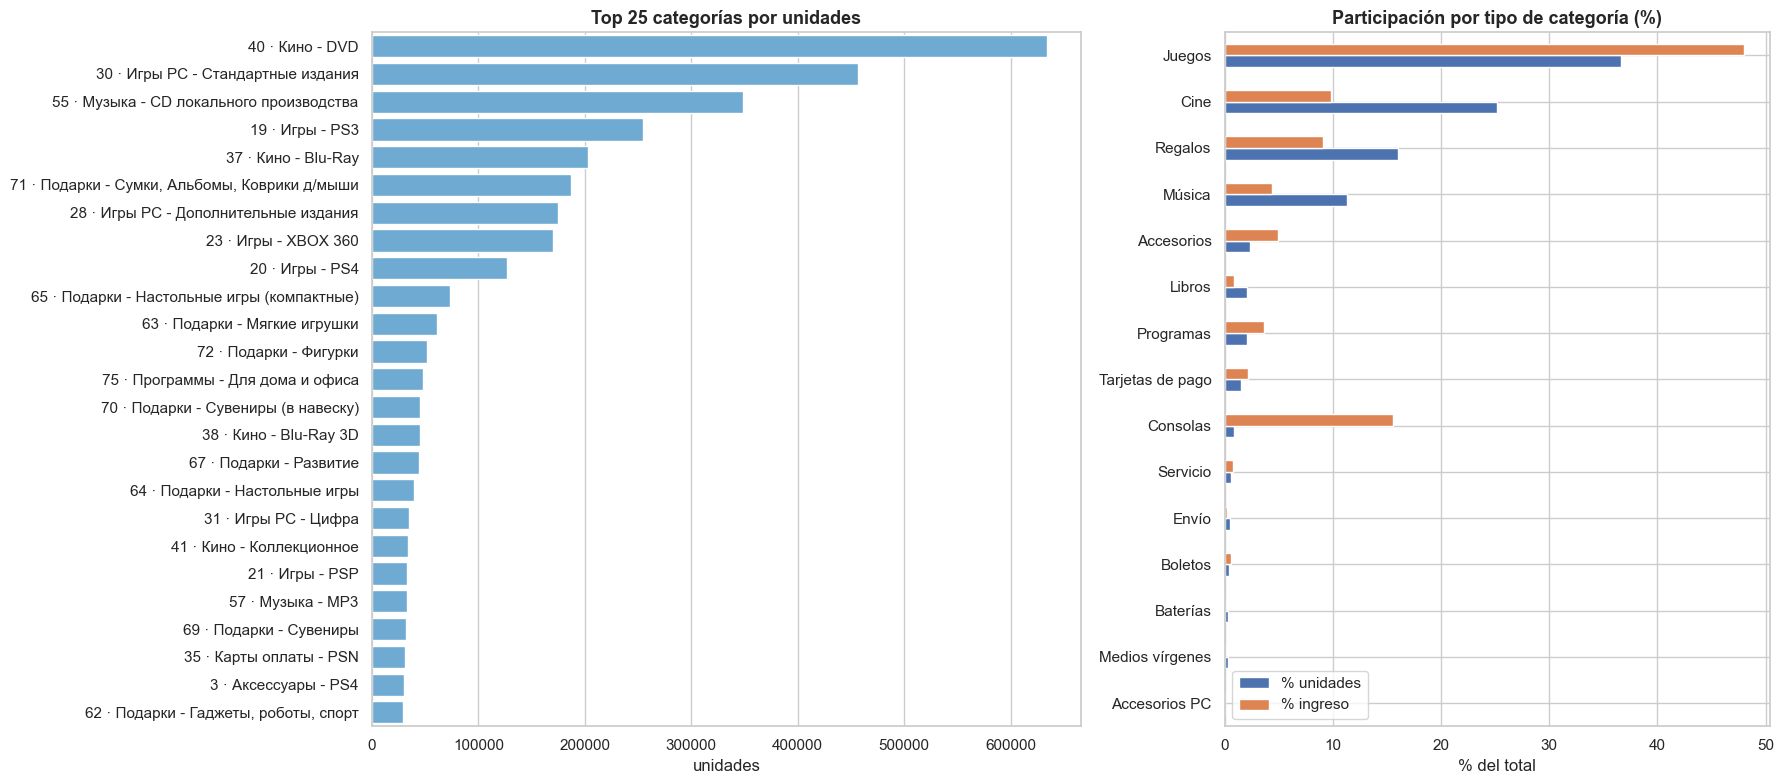

In [152]:
cat_plot = (df.groupby(["item_category_id", "item_category_name"])["item_cnt_day"].sum()
              .nlargest(25).reset_index())
cat_plot["label"] = cat_plot["item_category_id"].astype(str) + " · " + cat_plot["item_category_name"]
tipo_plot = df.groupby("cat_type_es").agg(unidades=("item_cnt_day", "sum"),
                                          ingreso=("revenue", "sum")).sort_values("unidades")

fig, axes = plt.subplots(1, 2, figsize=(18, 8), gridspec_kw={"width_ratios": [1.3, 1]})
sns.barplot(data=cat_plot, y="label", x="item_cnt_day", ax=axes[0], color="#5dade2")
axes[0].set(title="Top 25 categorías por unidades", xlabel="unidades", ylabel="")
tipo_plot[["unidades"]].div(tipo_plot["unidades"].sum()).mul(100).join(
    tipo_plot[["ingreso"]].div(tipo_plot["ingreso"].sum()).mul(100)).plot.barh(ax=axes[1])
axes[1].set(title="Participación por tipo de categoría (%)", xlabel="% del total", ylabel="")
axes[1].legend(["% unidades", "% ingreso"])
plt.tight_layout(); savefig("08c_categorias"); plt.show()

### 8.d Heatmaps: ventas en el tiempo por sucursal y por categoría

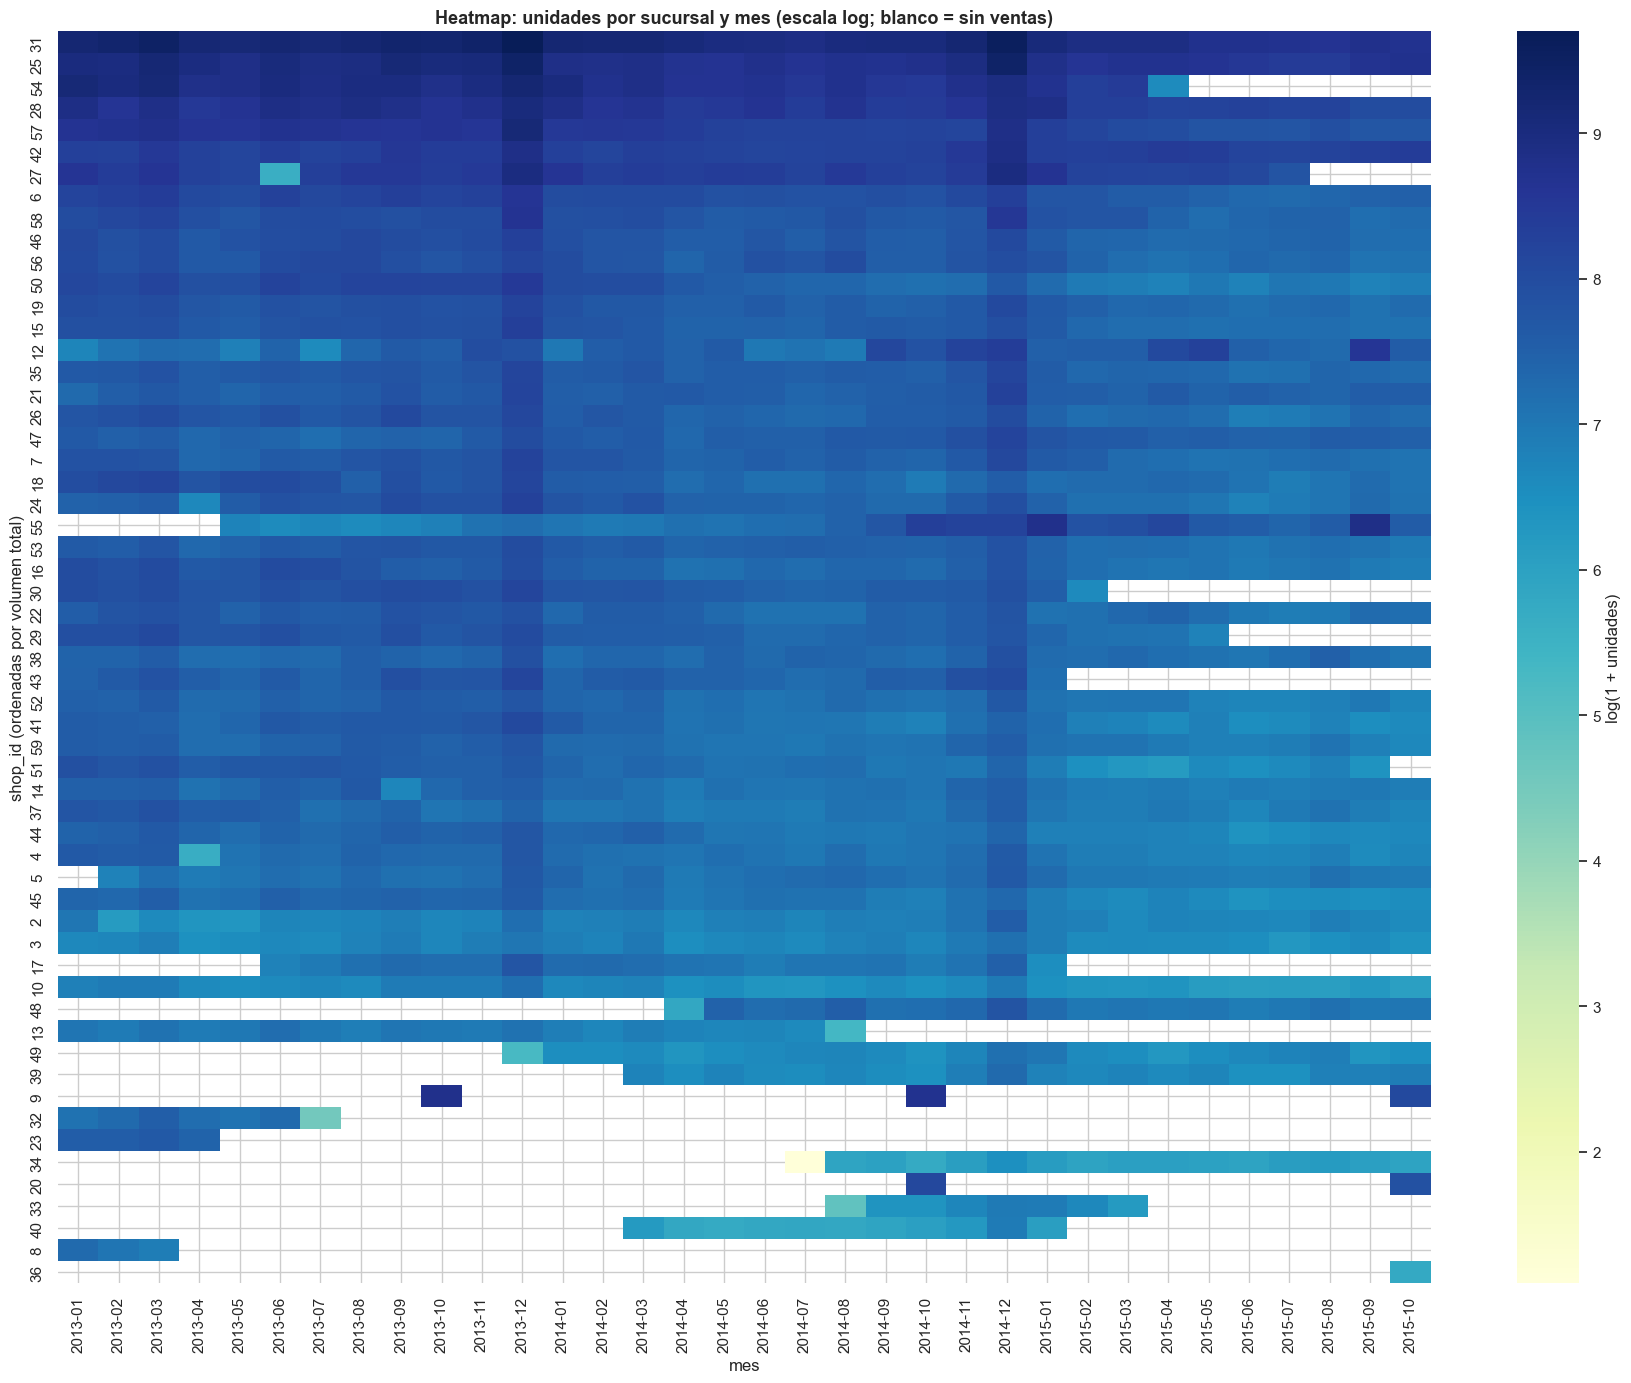

In [153]:
hm_t = df.groupby(["shop_id", "date_block_num"])["item_cnt_day"].sum().unstack(fill_value=0)
hm_t = hm_t.loc[hm_t.sum(axis=1).sort_values(ascending=False).index]
hm_t.columns = [str(p) for p in pd.period_range("2013-01", periods=hm_t.shape[1], freq="M")]

fig, ax = plt.subplots(figsize=(18, 14))
hm_t = hm_t.clip(lower=0)      # meses con ventas netas negativas (solo devoluciones) → 0
sns.heatmap(np.log1p(hm_t), mask=(hm_t == 0), cmap="YlGnBu", ax=ax,
            cbar_kws={"label": "log(1 + unidades)"}, yticklabels=[f"{i}" for i in hm_t.index])
ax.set(title="Heatmap: unidades por sucursal y mes (escala log; blanco = sin ventas)",
       xlabel="mes", ylabel="shop_id (ordenadas por volumen total)")
plt.tight_layout(); savefig("08d_heatmap_tienda_mes"); plt.show()

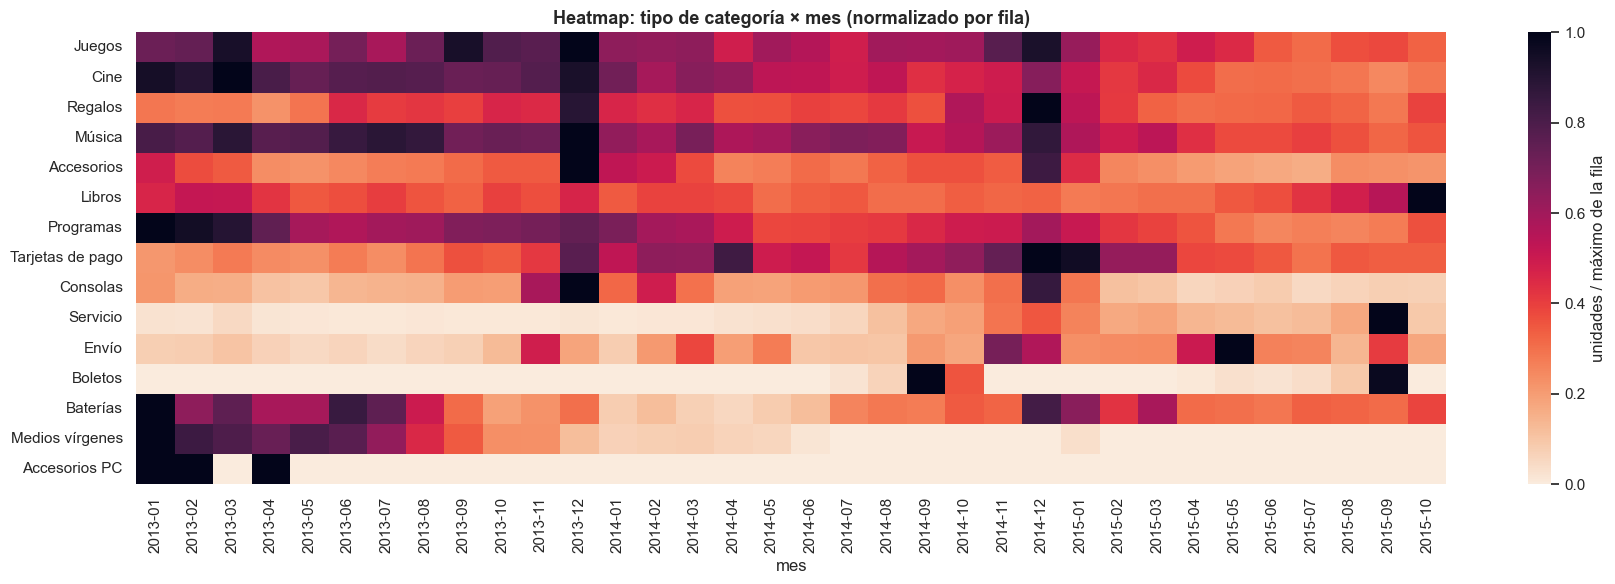

In [154]:
hm_c = df.groupby(["cat_type_es", "date_block_num"])["item_cnt_day"].sum().unstack(fill_value=0)
hm_c = hm_c.loc[hm_c.sum(axis=1).sort_values(ascending=False).index]
hm_c_norm = hm_c.div(hm_c.max(axis=1), axis=0)          # cada fila normalizada a su máximo
hm_c_norm.columns = hm_t.columns

fig, ax = plt.subplots(figsize=(18, 6))
sns.heatmap(hm_c_norm, cmap="rocket_r", ax=ax, cbar_kws={"label": "unidades / máximo de la fila"})
ax.set(title="Heatmap: tipo de categoría × mes (normalizado por fila)", xlabel="mes", ylabel="")
plt.tight_layout(); savefig("08d_heatmap_categoria_mes"); plt.show()

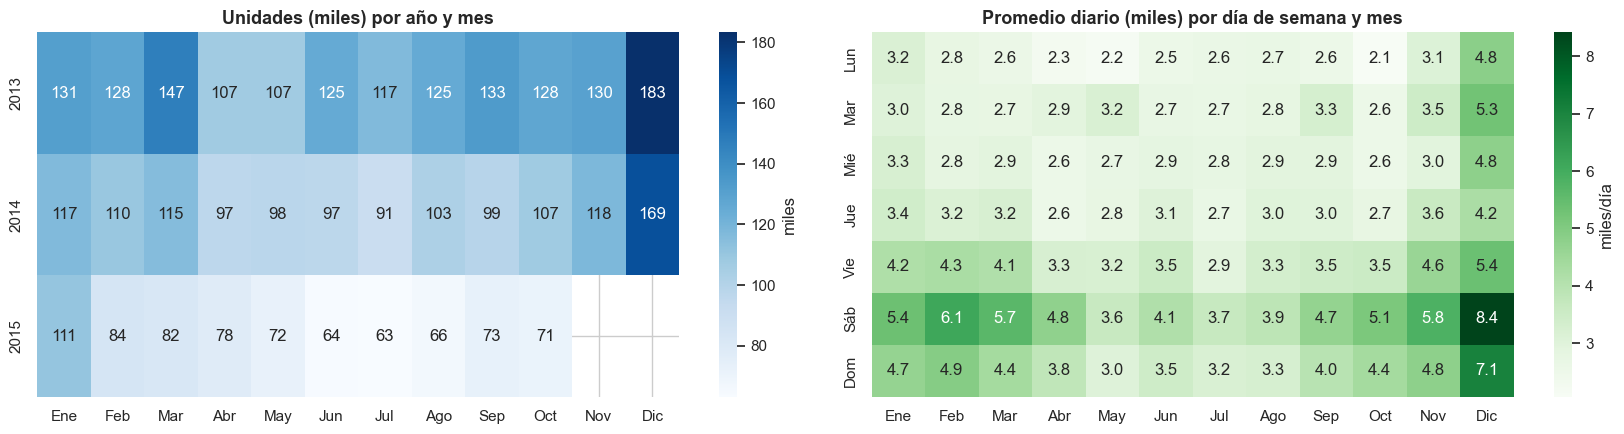

In [155]:
# Heatmap año x mes (estacionalidad) y día de semana x mes
fig, axes = plt.subplots(1, 2, figsize=(17, 4.5))
am = mens_df.pivot(index="anio", columns="mes", values="unidades")
am.columns = meses_nombre[:am.shape[1]]
sns.heatmap(am / 1e3, annot=True, fmt=".0f", cmap="Blues", ax=axes[0], cbar_kws={"label": "miles"})
axes[0].set(title="Unidades (miles) por año y mes", xlabel="", ylabel="")
dm = diaria.assign(dow=diaria.index.dayofweek, mes=diaria.index.month).pivot_table(
    index="dow", columns="mes", values="unidades", aggfunc="mean")
dm.index = dias_es; dm.columns = meses_nombre
sns.heatmap(dm / 1e3, annot=True, fmt=".1f", cmap="Greens", ax=axes[1], cbar_kws={"label": "miles/día"})
axes[1].set(title="Promedio diario (miles) por día de semana y mes", xlabel="", ylabel="")
plt.tight_layout(); savefig("08d_heatmap_calendario"); plt.show()

**Lectura de las visualizaciones clave:**

- **8.a Serie total:** tendencia descendente con dos picos idénticos en diciembre; la estacionalidad anual es la señal
  más fuerte de la serie agregada.
- **8.b Sucursales:** distribución muy asimétrica; unas 7 tiendas grandes (Moscú, Khimki, Yakutsk, San Petersburgo)
  dominan. Las barras rojas (tiendas que no están en test) incluyen tiendas grandes ya cerradas, como la 54 y la 27.
- **8.c Productos y categorías:** juegos (PC, PS3, Xbox 360) y tarjetas de pago dominan el top‑20. El gráfico de
  participación muestra la diferencia entre **volumen** (Cine, Música, Regalos) y **valor** (Juegos, Consolas).
- **8.d Heatmaps:**
  - *Tienda × mes:* se ven claramente las aperturas (celdas vacías a la izquierda: 48, 49, 39, 34, 36), los cierres
    (vacías a la derecha: 54, 27, 30, 29, 43, 17, 13) y las tiendas de evento (9, 20, solo en octubre). Las tiendas que
    operan los 34 meses se ven "más claras" en 2015 (caída general).
  - *Categoría × mes:* Juegos, Consolas y Accesorios tienen su máximo en diciembre y en meses de lanzamientos; **Cine y
    Música pierden peso** año con año (declive del formato físico); **Libros** crece hacia el final; **Medios vírgenes y
    Baterías prácticamente desaparecen**. → La categoría es una variable clave porque cada una tiene su propia tendencia.
  - *Año × mes / día de semana × mes:* confirman diciembre como el mes más fuerte en todos los años y el sábado como
    el mejor día en todos los meses.

## 9. Autocorrelación (ACF) y autocorrelación parcial (PACF)

- **ACF** (rezago *k*): correlación entre la serie y ella misma desplazada *k* períodos. Bandas de confianza al 95 %
  con la fórmula de Bartlett.
- **PACF** (rezago *k*): correlación con el rezago *k* **eliminando el efecto de los rezagos intermedios**
  (algoritmo de Durbin‑Levinson). Banda: ±1.96/√n. Sugiere el orden *p* de un AR(p).

Se implementan con NumPy (mismos resultados que `statsmodels.graphics.tsaplots.plot_acf / plot_pacf`), para no
depender de librerías extra. Con 34 observaciones mensuales el máximo rezago razonable es 16 (n/2 − 1).

In [156]:
def acf(x, nlags):
    x = np.asarray(x, float) - np.mean(x)
    d = np.sum(x ** 2)
    return np.array([1.0] + [np.sum(x[k:] * x[:-k]) / d for k in range(1, nlags + 1)])

def pacf(x, nlags):
    """PACF por Durbin-Levinson (equivalente a Yule-Walker)."""
    r = acf(x, nlags)
    out, phi = [1.0], np.zeros((nlags + 1, nlags + 1))
    for k in range(1, nlags + 1):
        num = r[k] - np.sum(phi[k - 1, 1:k] * r[1:k][::-1])
        den = 1 - np.sum(phi[k - 1, 1:k] * r[1:k])
        phi[k, k] = num / den
        for j in range(1, k):
            phi[k, j] = phi[k - 1, j] - phi[k, k] * phi[k - 1, k - j]
        out.append(phi[k, k])
    return np.array(out)

def plot_acf_pacf(series, titulo, nlags, axes):
    x = np.asarray(series, float); n = len(x)
    r, p = acf(x, nlags), pacf(x, nlags)
    se_acf = 1.96 * np.sqrt(np.r_[1 / n, (1 + 2 * np.cumsum(r[1:-1] ** 2)) / n])
    lags = np.arange(nlags + 1)
    for ax, vals, banda, nombre in [(axes[0], r, se_acf, "ACF"), (axes[1], p, None, "PACF")]:
        ax.vlines(lags, 0, vals, color="tab:blue"); ax.scatter(lags, vals, s=14, color="tab:blue", zorder=3)
        ax.axhline(0, color="black", lw=0.8)
        if banda is not None:
            ax.fill_between(lags[1:], -banda, banda, color="tab:blue", alpha=0.15)
        else:
            ax.axhspan(-1.96 / np.sqrt(n), 1.96 / np.sqrt(n), color="tab:blue", alpha=0.15)
        ax.set(title=f"{nombre} — {titulo}", ylim=(-1.05, 1.05), xlabel="rezago")
    lim = np.r_[np.inf, se_acf]
    sig_acf = [k for k in range(1, nlags + 1) if abs(r[k]) > se_acf[k - 1]]
    sig_pacf = [k for k in range(1, nlags + 1) if abs(p[k]) > 1.96 / np.sqrt(n)]
    return {"serie": titulo, "n": n, "ACF lag1": round(r[1], 2),
            "ACF lag12": round(r[12], 2) if nlags >= 12 else None,
            "rezagos ACF signif.": sig_acf, "rezagos PACF signif.": sig_pacf}

resultados_acf = []
# Categorías que NO son productos (bolsas, envíos, servicios, boletos): se excluyen de las series por producto
NO_PRODUCTO = [8, 9, 71, 79, 80]
items_no_producto = set(items.loc[items["item_category_id"].isin(NO_PRODUCTO), "item_id"])

### 9.1 Ventas totales — mensual y diaria

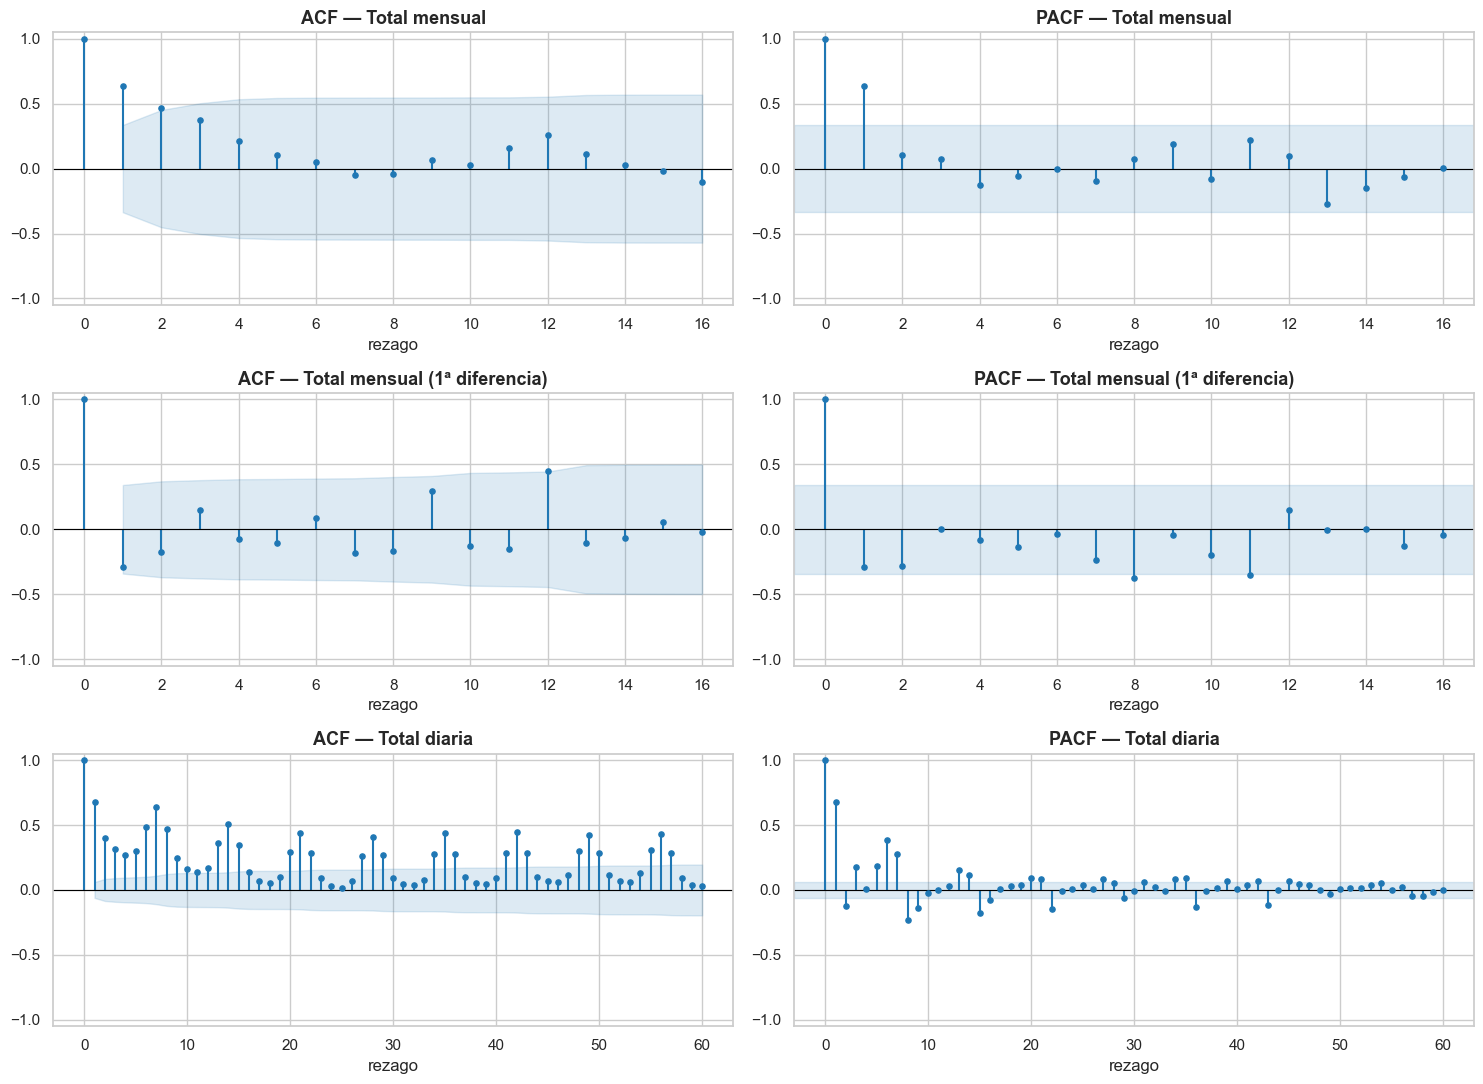

,serie,n,ACF lag1,ACF lag12,rezagos ACF signif.,rezagos PACF signif.
0,Total mensual,34,0.64,0.26,"[1, 2]",[1]
1,Total mensual (1ª diferencia),33,-0.29,0.45,[12],"[8, 11]"
2,Total diaria,1034,0.68,0.17,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14...","[1, 2, 3, 5, 6, 7, 8, 9, 13, 14, 15, 16, 20, 2..."


In [157]:
fig, axes = plt.subplots(3, 2, figsize=(15, 11))
resultados_acf.append(plot_acf_pacf(mensual["unidades"], "Total mensual", 16, axes[0]))
resultados_acf.append(plot_acf_pacf(mensual["unidades"].diff().dropna(), "Total mensual (1ª diferencia)", 16, axes[1]))
resultados_acf.append(plot_acf_pacf(diaria["unidades"], "Total diaria", 60, axes[2]))
plt.tight_layout(); savefig("09_acf_pacf_total"); plt.show()
pd.DataFrame(resultados_acf)

### 9.2 Ventas por sucursal (top 3 tiendas activas en test)

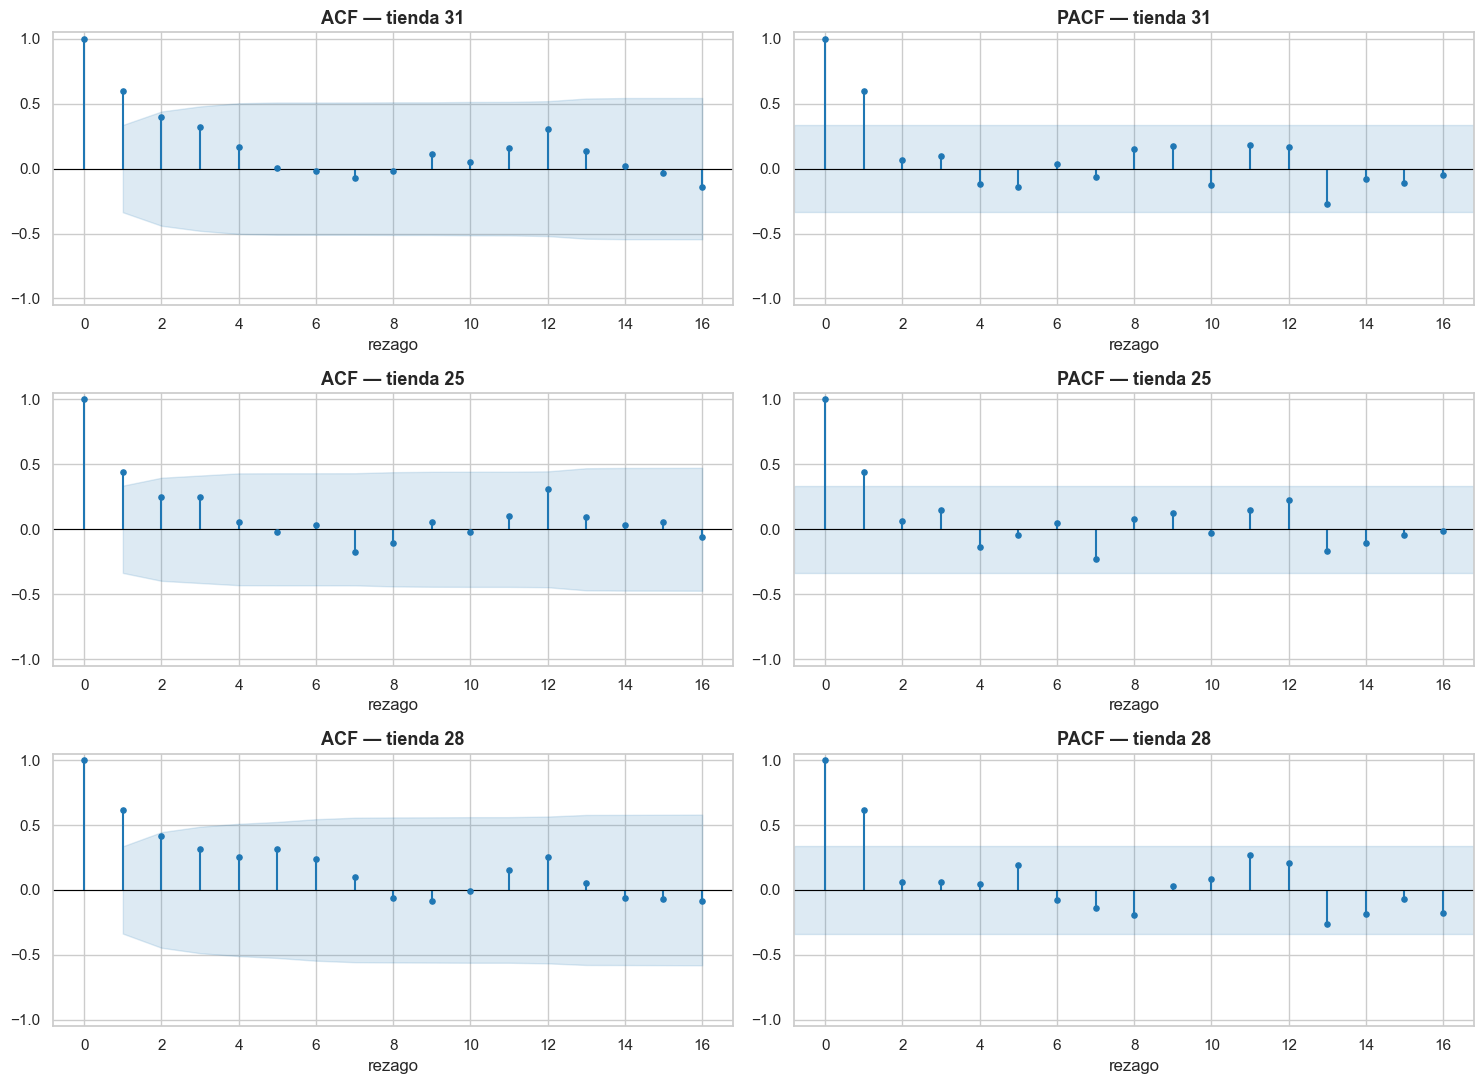

,serie,n,ACF lag1,ACF lag12,rezagos ACF signif.,rezagos PACF signif.
0,tienda 31,34,0.60,0.31,[1],[1]
1,tienda 25,34,0.44,0.31,[1],[1]
2,tienda 28,34,0.61,0.25,[1],[1]


In [158]:
top_shops = (df[df["shop_id"].isin(test["shop_id"])].groupby("shop_id")["item_cnt_day"].sum()
               .nlargest(3).index.tolist())
fig, axes = plt.subplots(3, 2, figsize=(15, 11))
res_shop = []
for i, s in enumerate(top_shops):
    serie = tienda_mes.loc[s].reindex(range(34), fill_value=0)
    res_shop.append(plot_acf_pacf(serie, f"tienda {s}", 16, axes[i]))
plt.tight_layout(); savefig("09_acf_pacf_tiendas"); plt.show()
pd.DataFrame(res_shop)

### 9.3 Ventas por producto (top 3 productos con ventas en ≥ 30 meses, excluyendo bolsas/servicios)

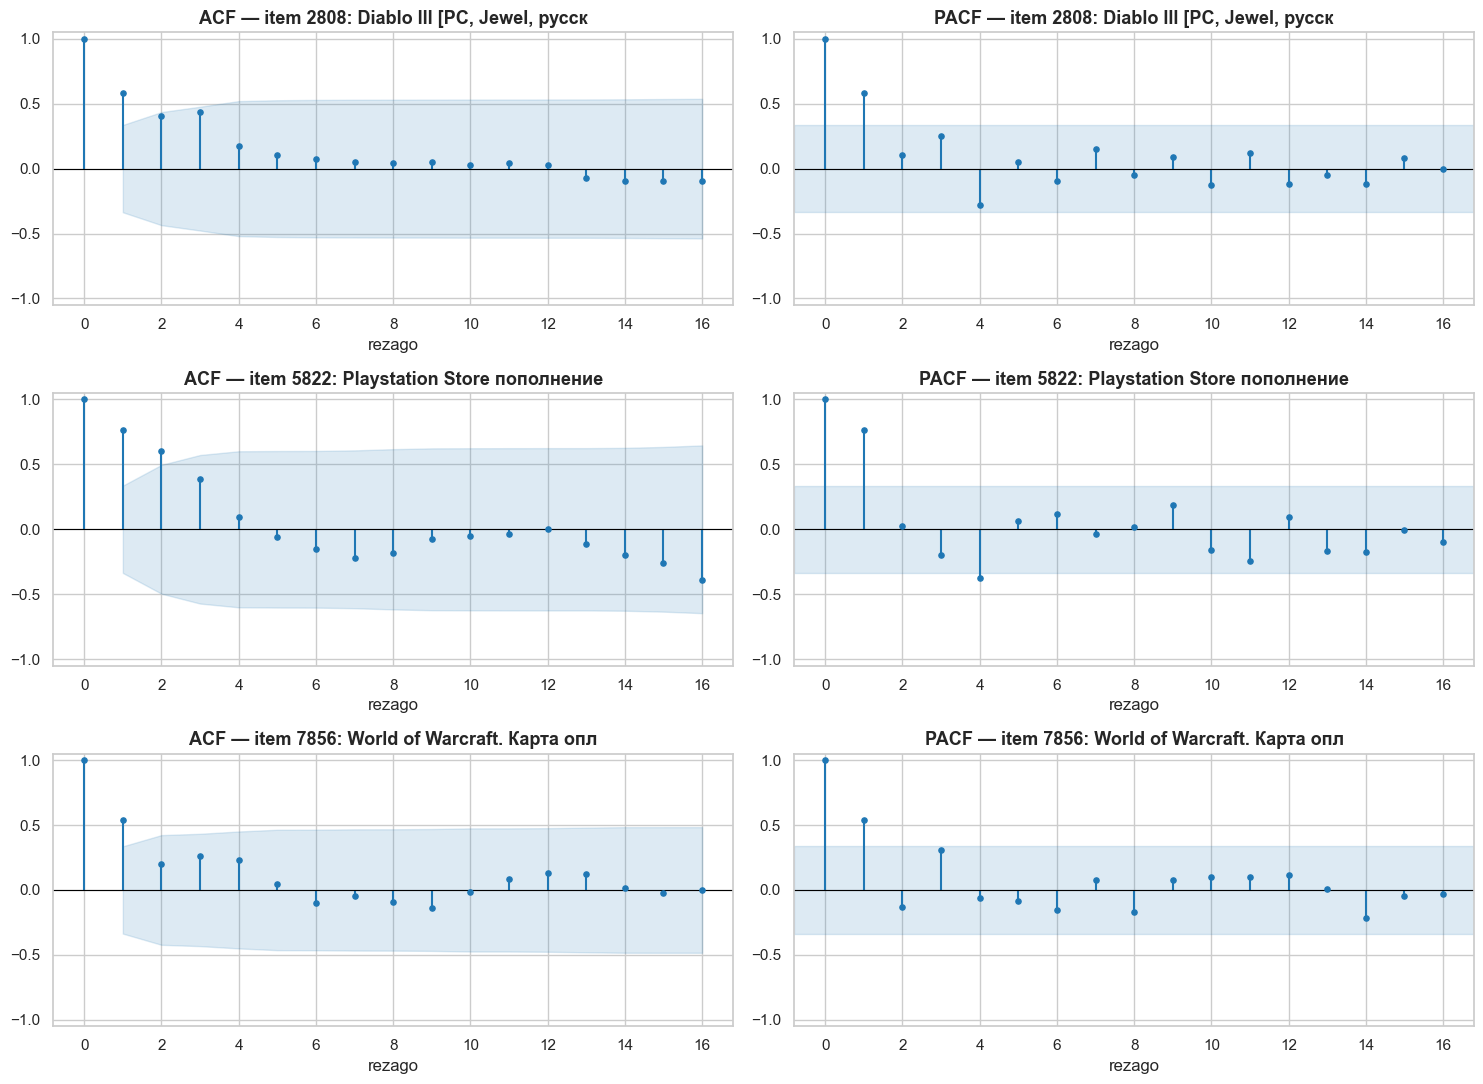

,serie,n,ACF lag1,ACF lag12,rezagos ACF signif.,rezagos PACF signif.
0,"item 2808: Diablo III [PC, Jewel, русск",34,0.58,0.03,[1],[1]
1,item 5822: Playstation Store пополнение,34,0.77,0.00,"[1, 2]","[1, 4]"
2,item 7856: World of Warcraft. Карта опл,34,0.54,0.13,[1],[1]


In [159]:
item_mes = df.groupby(["item_id", "date_block_num"])["item_cnt_day"].sum().unstack(fill_value=0)
item_mes = item_mes.reindex(columns=range(34), fill_value=0)
# Productos con ventas en (casi) todos los meses: son los únicos con series útiles para ACF
candidatos = item_mes[(item_mes > 0).sum(axis=1) >= 30]
top_prod = [i for i in candidatos.sum(axis=1).sort_values(ascending=False).index
            if i not in items_no_producto][:3]

fig, axes = plt.subplots(3, 2, figsize=(15, 11))
res_item = []
for i, it_ in enumerate(top_prod):
    res_item.append(plot_acf_pacf(item_mes.loc[it_], f"item {it_}: {nombres[it_][:28]}", 16, axes[i]))
plt.tight_layout(); savefig("09_acf_pacf_productos"); plt.show()
pd.DataFrame(res_item)

### 9.4 Ventas por par sucursal‑producto (top 3 pares con ventas en ≥ 30 meses, sin envíos/servicios)

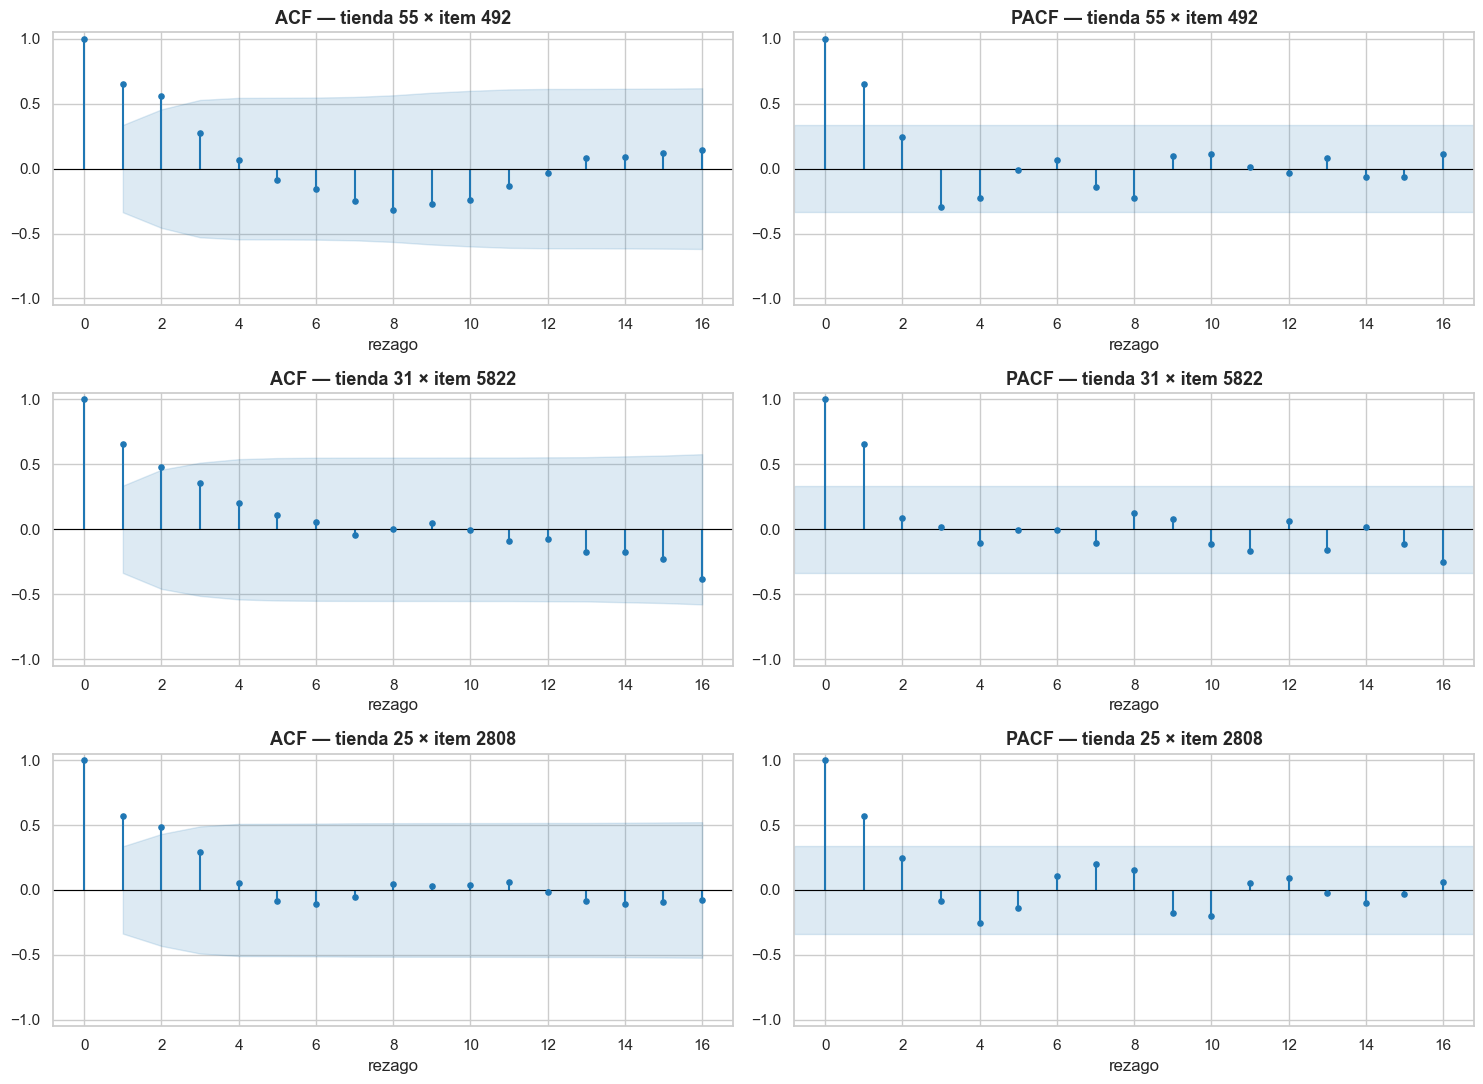

,serie,n,ACF lag1,ACF lag12,rezagos ACF signif.,rezagos PACF signif.
0,tienda 55 × item 492,34,0.65,-0.03,"[1, 2]",[1]
1,tienda 31 × item 5822,34,0.66,-0.08,"[1, 2]",[1]
2,tienda 25 × item 2808,34,0.57,-0.02,"[1, 2]",[1]


In [160]:
par_mes = df.groupby(["shop_id", "item_id", "date_block_num"])["item_cnt_day"].sum().unstack(fill_value=0)
par_mes = par_mes.reindex(columns=range(34), fill_value=0)
cand = par_mes[(par_mes > 0).sum(axis=1) >= 30]
cand = cand[~cand.index.get_level_values("item_id").isin(items_no_producto)]
top_pares = cand.sum(axis=1).nlargest(3).index.tolist()

fig, axes = plt.subplots(3, 2, figsize=(15, 11))
res_par = []
for i, (s, it_) in enumerate(top_pares):
    res_par.append(plot_acf_pacf(par_mes.loc[(s, it_)], f"tienda {s} × item {it_}", 16, axes[i]))
plt.tight_layout(); savefig("09_acf_pacf_pares"); plt.show()
pd.DataFrame(res_par)

In [161]:
# Panorama general: distribución del ACF en rezago 1 y 12 para muchas series tienda-producto
pares_largos = par_mes[(par_mes > 0).sum(axis=1) >= 20]
acf1 = pares_largos.apply(lambda r: acf(r.values, 12)[1], axis=1)
acf12 = pares_largos.apply(lambda r: acf(r.values, 12)[12], axis=1)
print(f"Pares tienda-producto con ventas en >= 20 de 34 meses: {len(pares_largos):,}")
print(f"ACF(1) mediana: {acf1.median():.2f} | % con ACF(1) > banda 95% (0.34): {100*(acf1 > 0.34).mean():.1f}%")
print(f"ACF(12) mediana: {acf12.median():.2f} | % con ACF(12) > 0.34: {100*(acf12 > 0.34).mean():.1f}%")

Pares tienda-producto con ventas en >= 20 de 34 meses: 5,878
ACF(1) mediana: 0.32 | % con ACF(1) > banda 95% (0.34): 46.8%
ACF(12) mediana: -0.02 | % con ACF(12) > 0.34: 0.5%


### 9.5 Interpretación

**i. ¿Existen correlaciones significativas a diferentes rezagos?**

| Serie | Hallazgo ACF | Hallazgo PACF | Lectura |
|---|---|---|---|
| Total mensual | ACF(1)=0.64 y ACF(2) significativos, decaimiento lento | solo rezago 1 | Serie **no estacionaria** (tendencia); comportamiento tipo AR(1). |
| Total mensual, 1ª diferencia | **ACF(12)=0.45, significativo** | rezagos 8 y 11 al límite | Al quitar la tendencia aparece la **estacionalidad anual**. |
| Total diaria | picos en 7, 14, 21, 28… que no se apagan | rezagos 1–3, 5–9 y otros | **Estacionalidad semanal** fuerte; AR de orden alto o SARIMA con s=7. |
| Top 3 tiendas | ACF(1)=0.44–0.61 | solo rezago 1 | AR(1): el mes anterior es el mejor predictor. ACF(12)≈0.3, positivo pero no significativo. |
| Top 3 productos | ACF(1)=0.54–0.77 | rezago 1 (PSN: 1 y 4) | Fuerte persistencia, **ACF(12)≈0**: domina el ciclo de vida del producto, no la estación. |
| Top 3 pares tienda‑producto | ACF(1)≈0.57–0.66, rezagos 1–2 | solo rezago 1 | Mismo patrón AR(1). |
| 5,878 pares con ≥ 20 meses de venta | mediana ACF(1)=0.32; 47 % significativos | — | La persistencia es general. **ACF(12) mediana ≈ 0**; solo 0.5 % significativos. |

**ii. ¿Se observa estacionalidad reflejada en patrones repetitivos?**
- **Sí, a nivel agregado**: anual (rezago 12 en la serie mensual diferenciada) y semanal (rezagos múltiplos de 7 en la
  serie diaria).
- **No, a nivel tienda‑producto individual**: ahí la autocorrelación se concentra en los primeros 1–2 rezagos.
  Cada producto tiene un ciclo de vida (lanzamiento → pico → declive) que pesa más que la estacionalidad.
- **Limitación:** con 34 meses solo hay ≈ 2.8 ciclos anuales, así que las bandas de confianza son anchas y el rezago 12
  tiene poca potencia estadística.

**Implicaciones para el modelo:** usar *lags* 1, 2 y 3 de `item_cnt_month` como variables principales; incluir el lag 12
y variables de calendario (mes, indicador de diciembre, número de fines de semana) **a nivel agregado** (promedios por
tienda o categoría) en lugar de por par individual.

## 10. Insights y conclusiones del EDA
### Cobertura de `test.csv` respecto al historial

In [162]:
pares_train = set(zip(df["shop_id"], df["item_id"]))
test["par_con_historial"] = [p in pares_train for p in zip(test["shop_id"], test["item_id"])]
test["item_en_train"] = test["item_id"].isin(df["item_id"])
oct15 = set(zip(df.loc[df["date_block_num"] == 33, "shop_id"], df.loc[df["date_block_num"] == 33, "item_id"]))
test["vendio_oct15"] = [p in oct15 for p in zip(test["shop_id"], test["item_id"])]

cobertura = pd.Series({
    "Pares en test": len(test),
    "Tiendas en test": test["shop_id"].nunique(),
    "Productos en test": test["item_id"].nunique(),
    "% pares con historial (tienda-producto vendido antes)": 100 * test["par_con_historial"].mean(),
    "% pares cuyo producto sí existe en train (otra tienda)": 100 * (test["item_en_train"] & ~test["par_con_historial"]).mean(),
    "% pares de producto NUEVO (nunca vendido)": 100 * (~test["item_en_train"]).mean(),
    "Productos nuevos (sin historial)": test.loc[~test["item_en_train"], "item_id"].nunique(),
    "% pares que vendieron en oct-2015": 100 * test["vendio_oct15"].mean(),
    "Test = producto cartesiano tiendas × productos": len(test) == test["shop_id"].nunique() * test["item_id"].nunique(),
})
cobertura.to_frame("valor")

,valor
Pares en test,214200
Tiendas en test,42
Productos en test,5100
% pares con historial (tienda-producto vendido antes),52.04
% pares cuyo producto sí existe en train (otra tienda),40.84
% pares de producto NUEVO (nunca vendido),7.12
Productos nuevos (sin historial),363
% pares que vendieron en oct-2015,13.39
Test = producto cartesiano tiendas × productos,True


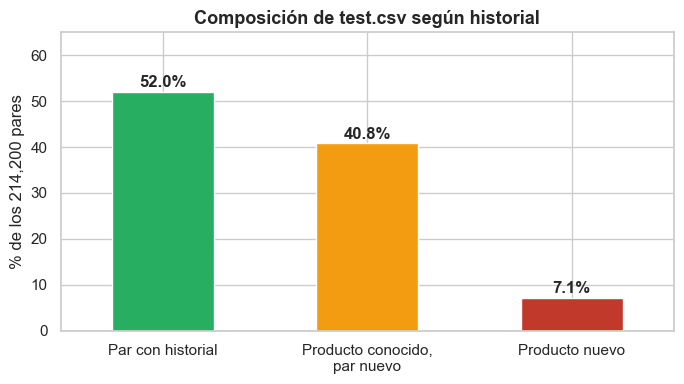

Categorías más frecuentes entre los productos NUEVOS de test:
item_category_name
Кино - DVD                             71
Музыка - CD локального производства    38
Подарки - Фигурки                      28
Игры PC - Цифра                        25
Книги - Комиксы, манга                 22
Музыка - Винил                         21
Игры - PS4                             18
Игры - Аксессуары для игр              12


In [163]:
fig, ax = plt.subplots(figsize=(7, 4))
grupos = pd.Series({"Par con historial": test["par_con_historial"].mean(),
                    "Producto conocido,\npar nuevo": (test["item_en_train"] & ~test["par_con_historial"]).mean(),
                    "Producto nuevo": (~test["item_en_train"]).mean()}) * 100
grupos.plot.bar(ax=ax, color=["#27ae60", "#f39c12", "#c0392b"], rot=0)
for i, v in enumerate(grupos):
    ax.text(i, v + 1, f"{v:.1f}%", ha="center", fontweight="bold")
ax.set(title="Composición de test.csv según historial", ylabel="% de los 214,200 pares", ylim=(0, 65))
plt.tight_layout(); savefig("10_cobertura_test"); plt.show()

# Categorías de los productos nuevos
nuevos = test.loc[~test["item_en_train"], ["item_id"]].drop_duplicates().merge(items, on="item_id") \
    .merge(categories[["item_category_id", "item_category_name"]], on="item_category_id")
print("Categorías más frecuentes entre los productos NUEVOS de test:")
print(nuevos["item_category_name"].value_counts().head(8).to_string())

### Guardar datos limpios para la siguiente etapa

In [164]:
PROC = ROOT / "data" / "processed"
PROC.mkdir(parents=True, exist_ok=True)
mensual_par = (df.groupby(["date_block_num", "shop_id", "item_id"])
                 .agg(item_cnt_month=("item_cnt_day", "sum"), item_price_mean=("item_price", "mean"))
                 .reset_index())
mensual_par.to_csv(PROC / "monthly_shop_item.csv", index=False)
print("Guardado data/processed/monthly_shop_item.csv:", mensual_par.shape)
print("Distribución de item_cnt_month (antes de recortar a [0, 20]):")
print(mensual_par["item_cnt_month"].describe(percentiles=[.5, .9, .99]).round(2).to_string())
print(f"% de valores > 20: {100 * (mensual_par['item_cnt_month'] > 20).mean():.2f}%")

Guardado data/processed/monthly_shop_item.csv: (1609122, 5)
Distribución de item_cnt_month (antes de recortar a [0, 20]):
count   1,609,122.00
mean            2.27
std             8.43
min           -22.00
50%             1.00
90%             4.00
99%            17.00
max         1,644.00
% de valores > 20: 0.71%


### Conclusiones

#### a. Variables que afectan directamente las ventas
1. **Historial reciente del par/producto** (lags 1–3): la autocorrelación en rezago 1 es la señal más consistente
   en todos los niveles.
2. **Categoría / tipo de producto:** define el nivel de ventas, el precio y la tendencia (Juegos y Consolas estables o
   al alza; Cine, Música y medios físicos en declive).
3. **Tienda y ciudad:** las diferencias de volumen entre sucursales son de hasta 28 veces; Moscú concentra el 35 %.
   Hay que distinguir tiendas físicas, online (12, 55), de evento (9, 20) y nuevas (36).
4. **Calendario:** mes del año (diciembre, y noviembre en menor medida), número de fines de semana del mes.
5. **Precio y antigüedad del producto:** los productos nuevos venden más en sus primeros meses (lanzamientos) y
   luego caen; el precio cambia con el tiempo (descuentos).

#### b. Patrones útiles para el forecasting
- **Noviembre 2015** es estacionalmente un mes **alto** (antesala de diciembre), pero la tendencia general es a la baja:
  se espera un nivel mayor al de octubre‑2015 y menor al de noviembre‑2014.
- **Cobertura de `test.csv`:**
  - **52.0 %** de los 214,200 pares tienda‑producto tiene historial en train.
  - **40.8 %** son productos conocidos, pero nunca vendidos en esa tienda.
  - **7.1 %** corresponde a **363 productos nuevos** sin ninguna venta (sí están en `items.csv`, así que se conoce su
    categoría y nombre).
  - Solo **13.4 %** de los pares vendió algo en oct‑2015.
- `test.csv` es el **producto cartesiano** 42 tiendas × 5,100 productos. Por eso el entrenamiento debe construirse
  con la misma lógica: una **matriz completa tienda × producto × mes con ceros**, no solo con las filas que tuvieron
  ventas. De lo contrario el modelo sobreestimará (la gran mayoría de los valores reales serán 0).
- Para pares y productos nuevos, las variables de **categoría, tienda, ciudad y texto del nombre** (p. ej. plataforma PS4,
  PC) son la única información disponible.
- El objetivo mensual tiene cola larga (máx. 1,644; 0.71 % > 20): recortarlo a **[0, 20]** como en Kaggle.

#### c. Calidad y preparación del dataset
| Aspecto | Resultado | Acción tomada |
|---|---|---|
| Nulos | 0 en todas las tablas | Ninguna |
| Fechas | 100 % convertibles; sin días faltantes; `date_block_num` consistente | Conversión a `datetime` |
| Duplicados exactos | 6 filas | Eliminadas |
| Precio ≤ 0 | 1 fila (−1) | Imputada con la mediana del mismo producto en la misma tienda y mes (o, si no hubiera, la del producto) |
| Devoluciones | 7,356 filas (0.25 %) | Conservadas (se netean al agregar) + bandera `is_return` |
| Outliers extremos | 3 filas (precio 307,980; cantidades 2,169 y 1,000) | Eliminadas |
| Tiendas duplicadas | 0=57, 1=58, 10=11 | Unificadas en train y test |
| Ítems no‑producto | bolsas, envíos, servicios, boletos | Identificados (categorías 8, 9, 71, 79, 80) |

**Veredicto:** el dataset es de **buena calidad estructural** (completo, consistente, sin problemas de formato). Los
problemas encontrados son pocos y ya están corregidos. El reto principal para el modelado **no es la limpieza sino la
dispersión**: muchos pares sin historial, muchos ceros y productos con ciclo de vida corto. La tabla mensual limpia
quedó guardada en `data/processed/monthly_shop_item.csv`, lista para la etapa de ingeniería de variables y forecasting.

---
## Anexo — Screenshots del `git pull` de cada integrante

Cada integrante clonó el repositorio y ejecutó `git pull origin main` en su computadora. Las capturas se guardan en
`reports/figures/` y la siguiente celda las muestra todas automáticamente:

| Integrante | Archivo |
|---|---|
| Kevin Alejandro Reyes Alvarez | `pull_integrante1.png` |
| Iñigo Alvarado Guirola | `pull_integrante2.png` |
| Amós Nehemías Illú Chapetón | `pull_integrante3.png` |

Capturas encontradas: 3 de 3 integrantes
  ✔  Kevin Alejandro Reyes Alvarez
  ✔  Iñigo Alvarado Guirola
  ✔  Amós Nehemías Illú Chapetón


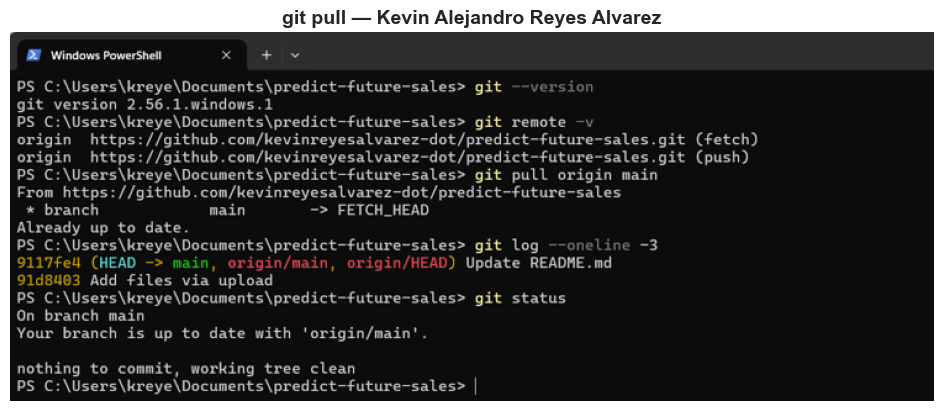

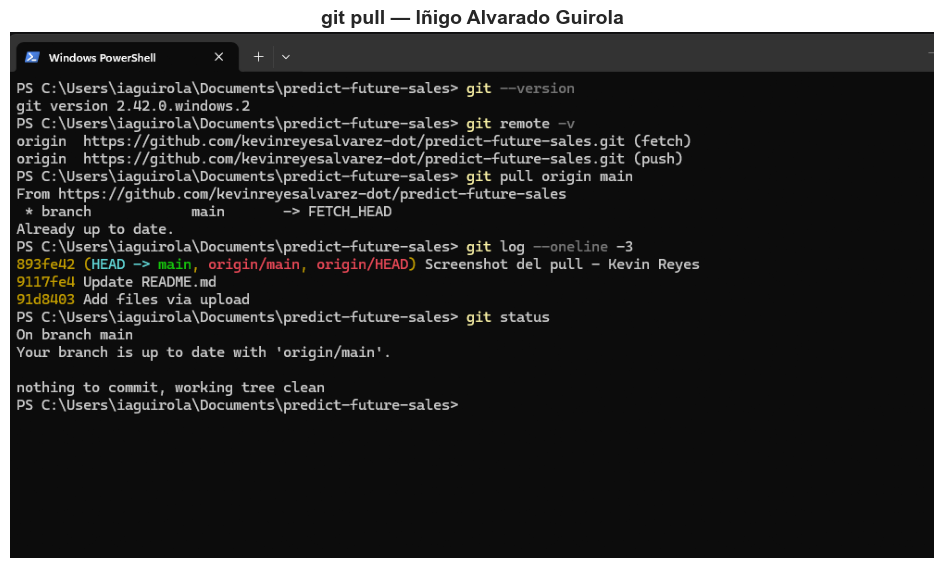

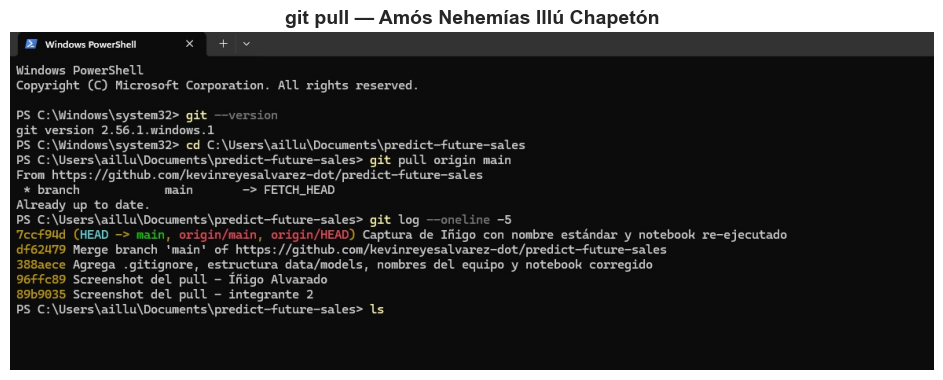

In [165]:
NOMBRES = {
    "pull_integrante1.png": "Kevin Alejandro Reyes Alvarez",
    "pull_integrante2.png": "Iñigo Alvarado Guirola",
    "pull_integrante3.png": "Amós Nehemías Illú Chapetón",
}
capturas = sorted(FIG.glob("pull_*.png"))
print(f"Capturas encontradas: {len(capturas)} de {len(NOMBRES)} integrantes")
for archivo, nombre in NOMBRES.items():
    print(f"  {'✔' if (FIG / archivo).exists() else '✘ pendiente'}  {nombre}")

for p in capturas:
    img = plt.imread(p)
    alto, ancho = img.shape[:2]
    fig, ax = plt.subplots(figsize=(12, 12 * alto / ancho))
    ax.imshow(img); ax.axis("off")
    ax.set_title(f"git pull — {NOMBRES.get(p.name, p.stem)}", fontsize=14, fontweight="bold")
    plt.show()